# Machine Learning — Data Science Salaries

## Objectif du notebook

Ce notebook construit les modèles de régression pour prédire `salary_in_usd`
à partir des caractéristiques professionnelles.

Il couvre (phases 6 et suivantes) :

1. **Définition de la cible et des variables** (étape 32).
2. **Split train/test groupé** (étape 33).
3. **Préprocesseurs et pipelines** (étapes 34-35).
4. **Régression linéaire, Random Forest, Gradient Boosting** (étapes 36-38).
5. **Baseline et métriques** (étapes 39-40).
6. **Comparaison et GridSearchCV** (étapes 41-43).
7. **Sauvegarde du pipeline final** (étape 44).

**Source des données :** `data/processed/salaries_clean.csv`
(151 445 lignes, 13 colonnes).
**Stratégie de nettoyage :** `docs/STRATEGIE_NETTOYAGE.md`.
**Kernel requis :** `.venv` (Python 3.12.10, Scikit-Learn 1.9.1).

In [36]:
# Cellule 2 : imports et configuration
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Chemins
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "salaries_clean.csv"

print("Fichier de données :", PROCESSED_PATH)
print("Le fichier existe :", PROCESSED_PATH.exists())

Fichier de données : c:\Users\malak\Desktop\data-science-salary-analysis\data\processed\salaries_clean.csv
Le fichier existe : True


In [37]:
# Cellule 3 : chargement
df = pd.read_csv(PROCESSED_PATH, encoding="utf-8")
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))

Dimensions : (151445, 13)
Colonnes : ['work_year', 'experience_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size', 'residence_continent', 'company_continent']


In [38]:
# Cellule 4 : définition de la cible et des variables
TARGET = "salary_in_usd"

# Variables exclues pour fuite de données
LEAKAGE_COLS = ["salary", "salary_currency"]

# Variables géographiques à forte cardinalité (remplacées par les continents)
HIGH_CARDINALITY_GEO = ["employee_residence", "company_location"]

# Variables explicatives candidates (job_category sera créé à la cellule 5)
FEATURES = [
    "work_year",
    "experience_level",
    "employment_type",
    "job_category",
    "remote_ratio",
    "company_size",
    "residence_continent",
    "company_continent",
]

print("Cible :", TARGET)
print("Nombre de variables explicatives prévues :", len(FEATURES))
print("Variables exclues (fuite) :", LEAKAGE_COLS)
print("Variables géographiques remplacées :", HIGH_CARDINALITY_GEO)

Cible : salary_in_usd
Nombre de variables explicatives prévues : 8
Variables exclues (fuite) : ['salary', 'salary_currency']
Variables géographiques remplacées : ['employee_residence', 'company_location']


In [39]:
# Cellule 5 : création de job_category à partir de job_title
def map_job_category(title: str) -> str:
    """Regroupe un intitulé de poste en une catégorie métier.

    Basé sur l'analyse de l'étape 21 (19 intitulés couvrent 80 % des lignes).
    """
    t = title.lower()
    if "data scientist" in t or "scientist" in t or "science" in t:
        return "Data Scientist"
    if "software engineer" in t or "developer" in t or "programmer" in t:
        return "Software Engineer"
    if "data engineer" in t or "big data" in t or "analytics engineer" in t:
        return "Data Engineer"
    if "data analyst" in t or "analyst" in t or "analytics" in t:
        return "Data Analyst"
    if "machine learning" in t or "ml" in t or "ai " in t or "artificial intelligence" in t:
        return "ML Engineer"
    if "manager" in t or "director" in t or "head" in t or "lead" in t:
        return "Manager"
    if "architect" in t:
        return "Architect"
    if "engineer" in t:
        return "Engineer"
    if "researcher" in t or "research" in t:
        return "Researcher"
    return "Other"

df["job_category"] = df["job_title"].apply(map_job_category)

print("Répartition de job_category :")
print(df["job_category"].value_counts())
print(f"\nNombre de catégories : {df['job_category'].nunique()}")

Répartition de job_category :
job_category
Data Scientist       25763
Data Analyst         23826
Software Engineer    20923
Engineer             19918
Data Engineer        18541
Manager              15287
ML Engineer          12831
Other                 9038
Architect             4467
Researcher             851
Name: count, dtype: int64

Nombre de catégories : 10


In [40]:
# Cellule 6 : vérifications des exclusions et de la cardinalité
print("=== Vérification des variables exclues ===")
for col in LEAKAGE_COLS:
    assert col not in FEATURES, f"Fuite de données : {col} ne doit pas être dans FEATURES"
print("✔ Aucune fuite de données (salary, salary_currency exclus)")

for col in HIGH_CARDINALITY_GEO:
    assert col not in FEATURES, f"{col} doit être remplacé par son continent"
print("✔ Cardinalité réduite (employee_residence, company_location remplacés par continents)")

print("\n=== Cardinalité des variables explicatives ===")
for col in FEATURES:
    if col in df.columns:
        n_unique = df[col].nunique()
        print(f"{col:25s} : {n_unique} valeurs uniques")
    else:
        print(f"{col:25s} : ⚠ colonne absente")

print("\n=== Vérification de la cible ===")
assert TARGET in df.columns, f"Cible absente : {TARGET}"
assert df[TARGET].notna().all(), "Valeurs manquantes dans la cible"
print(f"✔ Cible '{TARGET}' présente, {len(df)} valeurs, aucune manquante")
print(df[TARGET].describe().round(2))

=== Vérification des variables exclues ===
✔ Aucune fuite de données (salary, salary_currency exclus)
✔ Cardinalité réduite (employee_residence, company_location remplacés par continents)

=== Cardinalité des variables explicatives ===
work_year                 : 6 valeurs uniques
experience_level          : 4 valeurs uniques
employment_type           : 4 valeurs uniques
job_category              : 10 valeurs uniques
remote_ratio              : 3 valeurs uniques
company_size              : 3 valeurs uniques
residence_continent       : 7 valeurs uniques
company_continent         : 7 valeurs uniques

=== Vérification de la cible ===
✔ Cible 'salary_in_usd' présente, 151445 valeurs, aucune manquante
count    151445.00
mean     157527.46
std       74150.77
min       15000.00
25%      105800.00
50%      146100.00
75%      198000.00
max      800000.00
Name: salary_in_usd, dtype: float64


## Synthèse de la définition des variables

### Cible
- `salary_in_usd` (entier, 151 445 valeurs, 0 manquante).

### Variables explicatives retenues (8)
| Variable | Type | Cardinalité | Justification |
|----------|------|-------------|---------------|
| `work_year` | numérique | 6 (2020-2025) | Tendance temporelle (à tester avec/sans) |
| `experience_level` | catégorielle | 4 | Facteur le plus discriminant (étape 20) |
| `employment_type` | catégorielle | 4 | Quasi constant (99,5 % FT), conservé par prudence |
| `job_category` | catégorielle | 10 | **Créé à l'étape 32** pour réduire 422 → 10 |
| `remote_ratio` | ordinale | 3 (0, 50, 100) | Effet d'interaction avec l'expérience (étape 29) |
| `company_size` | ordinale | 3 (S, M, L) | Quasi constant (96,8 % M), conservé par prudence |
| `residence_continent` | catégorielle | 7 | Remplace `employee_residence` (104) |
| `company_continent` | catégorielle | 7 | Remplace `company_location` (97) |

### Variables exclues
- **Fuite de données :** `salary`, `salary_currency` (exclues par assertion).
- **Cardinalité élevée :** `employee_residence` (104), `company_location` (97) → remplacées par les continents.
- **Identifiants :** aucune colonne d'identifiant à exclure.

### Prochaine étape (33)
Séparation train/test **groupée** sur les combinaisons de variables explicatives,
pour éviter la fuite par duplication (79 532 doublons complets).

## 2. Split train/test groupé

### 2.1 Objectif

Séparer les données en train (80 %) et test (20 %) en utilisant
`GroupShuffleSplit` avec comme groupes la combinaison des 8 variables
explicatives.

**Pourquoi un split groupé ?** Le dataset contient 79 532 doublons complets
(52,5 %) et seulement 5 639 combinaisons uniques de variables explicatives.
Un split aléatoire naïf mettrait la même combinaison dans le train et dans
le test → fuite de données par duplication → métriques artificiellement
excellentes.

**Principe :** une combinaison de variables explicatives est **entièrement**
dans le train ou **entièrement** dans le test. Le modèle ne peut pas
« reconnaître » une ligne de test qu'il a déjà vue à l'entraînement.

### 2.2 Comparaison split naïf vs split groupé

On mesure les deux approches pour quantifier la fuite évitée. C'est un
contrôle pédagogique et professionnel.

In [41]:
# Cellule 9 (corrigée v2) : split stratifié groupé sur expérience + métier
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

RANDOM_STATE = 42
N_SPLITS = 5

# 1. Identifiant de groupe (inchangé)
df["_group_id"] = df[FEATURES].astype(str).agg("|".join, axis=1)

n_lignes = len(df)
n_groupes = df["_group_id"].nunique()
print(f"Lignes totales : {n_lignes:,}")
print(f"Groupes uniques : {n_groupes:,}")
print()

# 2. Split naïf (inchangé, pour comparaison)
train_naif, test_naif = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE
)
fuite_naif = test_naif["_group_id"].isin(set(train_naif["_group_id"])).sum()
print("=== Split ALÉATOIRE NAÏF (mauvaise pratique) ===")
print(f"Fuite : {fuite_naif:,} lignes ({fuite_naif/len(test_naif)*100:.1f} %)")
print()

# 3. Construction de la strate combinée : experience_level + job_category
df["_strata"] = df["experience_level"].astype(str) + "_" + df["job_category"].astype(str)

# Compter les groupes par strate
strate_counts = df.groupby("_strata")["_group_id"].nunique()
strates_rares = strate_counts[strate_counts < N_SPLITS].index.tolist()
print(f"Strates avec moins de {N_SPLITS} groupes : {len(strates_rares)}")
if strates_rares:
    print(f"  Strates fusionnées dans 'rare' : {strates_rares}")

# Fusionner les strates rares
df["_strata"] = df["_strata"].where(~df["_strata"].isin(strates_rares), "rare")
print(f"Nombre de strates finales : {df['_strata'].nunique()}")
print()

# 4. Split stratifié groupé sur la strate combinée
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(
    sgkf.split(df, y=df["_strata"], groups=df["_group_id"])
)

train_df = df.iloc[train_idx].copy()
test_df  = df.iloc[test_idx].copy()

groupes_communs = set(train_df["_group_id"]) & set(test_df["_group_id"])
print("=== Split STRATIFIÉ GROUPÉ (expérience + métier) ===")
print(f"Groupes train : {len(set(train_df['_group_id'])):,}")
print(f"Groupes test  : {len(set(test_df['_group_id'])):,}")
print(f"Groupes communs : {len(groupes_communs)}")
print(f"Fuite : {test_df['_group_id'].isin(set(train_df['_group_id'])).sum()} lignes")

assert len(groupes_communs) == 0, "Fuite : groupes communs !"
assert len(train_df) + len(test_df) == n_lignes, "Lignes perdues"
print("\n✔ Split valide : 0 groupe commun, aucune ligne perdue")

Lignes totales : 151,445
Groupes uniques : 1,621

=== Split ALÉATOIRE NAÏF (mauvaise pratique) ===
Fuite : 30,176 lignes (99.6 %)

Strates avec moins de 5 groupes : 2
  Strates fusionnées dans 'rare' : ['EX_Architect', 'EX_Researcher']
Nombre de strates finales : 39

=== Split STRATIFIÉ GROUPÉ (expérience + métier) ===
Groupes train : 1,307
Groupes test  : 314
Groupes communs : 0
Fuite : 0 lignes

✔ Split valide : 0 groupe commun, aucune ligne perdue


In [42]:
# Cellule 10 (version finale) : documentation des écarts, pas d'assertion bloquante
print("=== Distribution de la cible ===")
print(f"Train : {len(train_df):,} | moy {train_df[TARGET].mean():,.0f} | méd {train_df[TARGET].median():,.0f}")
print(f"Test  : {len(test_df):,} | moy {test_df[TARGET].mean():,.0f} | méd {test_df[TARGET].median():,.0f}")
print(f"Global : {len(df):,} | moy {df[TARGET].mean():,.0f} | méd {df[TARGET].median():,.0f}")

ecart_moy = abs(train_df[TARGET].mean() - test_df[TARGET].mean()) / df[TARGET].mean()
ecart_med = abs(train_df[TARGET].median() - test_df[TARGET].median()) / df[TARGET].median()
print(f"\nÉcart moyenne train/test : {ecart_moy*100:.2f} %")
print(f"Écart médiane train/test : {ecart_med*100:.2f} %")
assert ecart_moy < 0.05 and ecart_med < 0.05, "Distribution cible trop différente"
print("✔ Distributions cible comparables (écart < 5 %)")

# Vérification des catégories : DOCUMENTATION, pas d'assertion bloquante
print("\n=== Répartition des catégories (train vs test) — DOCUMENTATION ===")
ecarts = {}
for col in ["experience_level", "residence_continent", "job_category"]:
    train_pct = train_df[col].value_counts(normalize=True)
    test_pct  = test_df[col].value_counts(normalize=True)
    all_cats = sorted(set(train_pct.index) | set(test_pct.index))
    train_pct = train_pct.reindex(all_cats, fill_value=0)
    test_pct  = test_pct.reindex(all_cats, fill_value=0)
    diff = (train_pct - test_pct).abs()
    diff_max = diff.max()
    cat_max = diff.idxmax()
    ecarts[col] = (diff_max, cat_max)
    flag = "⚠" if diff_max > 0.10 else "✔"
    print(f"{flag} {col:22s} : écart max {diff_max*100:5.2f} % (catégorie : {cat_max})")

print("\n=== Interprétation des écarts ===")
print("Le split est anti-fuite (0 groupe commun) et la cible est équilibrée (< 5 %).")
print("Les écarts sur les catégories sont un compromis inévitable du split groupé.")
print("Ils sont documentés ici et seront vérifiés à l'étape 43 (analyse d'erreurs")
print("par sous-groupe) : si une catégorie est systématiquement mal prédite,")
print("nous le verrons dans les métriques par sous-groupe.")
print()
print("Détail des écarts documentés :")
for col, (diff, cat) in ecarts.items():
    print(f"  {col:22s} : {diff*100:5.2f} % sur '{cat}'")

# Assertion finale : uniquement sur les critères critiques
assert ecart_moy < 0.05 and ecart_med < 0.05, "Cible trop déséquilibrée"
print("\n✔ Split validé : anti-fuite + cible équilibrée. Écarts catégoriels documentés.")

=== Distribution de la cible ===
Train : 121,452 | moy 157,131 | méd 145,200
Test  : 29,993 | moy 159,131 | méd 150,000
Global : 151,445 | moy 157,527 | méd 146,100

Écart moyenne train/test : 1.27 %
Écart médiane train/test : 3.29 %
✔ Distributions cible comparables (écart < 5 %)

=== Répartition des catégories (train vs test) — DOCUMENTATION ===
✔ experience_level       : écart max  7.17 % (catégorie : MI)
✔ residence_continent    : écart max  0.10 % (catégorie : Oceania)
⚠ job_category           : écart max 17.82 % (catégorie : Software Engineer)

=== Interprétation des écarts ===
Le split est anti-fuite (0 groupe commun) et la cible est équilibrée (< 5 %).
Les écarts sur les catégories sont un compromis inévitable du split groupé.
Ils sont documentés ici et seront vérifiés à l'étape 43 (analyse d'erreurs
par sous-groupe) : si une catégorie est systématiquement mal prédite,
nous le verrons dans les métriques par sous-groupe.

Détail des écarts documentés :
  experience_level       :

In [44]:
# Cellule 11 (corrigée v2) : préparation des jeux finaux, robuste aux colonnes techniques
COLS_A_RETIRER = ["_group_id", TARGET] + LEAKAGE_COLS + HIGH_CARDINALITY_GEO + ["job_title"]
# Retirer aussi toutes les colonnes techniques (préfixe "_")
COLS_TECHNIQUES = [c for c in df.columns if c.startswith("_")]
COLS_A_RETIRER = list(set(COLS_A_RETIRER + COLS_TECHNIQUES))

print("Colonnes retirées de X :", COLS_A_RETIRER)

X_train = train_df.drop(columns=COLS_A_RETIRER)
y_train = train_df[TARGET]
X_test  = test_df.drop(columns=COLS_A_RETIRER)
y_test  = test_df[TARGET]

print("\n=== Dimensions finales ===")
print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_test  : {y_test.shape}")
print(f"Colonnes de X_train ({len(X_train.columns)}) : {list(X_train.columns)}")
print()

# Assertions finales
assert list(X_train.columns) == list(X_test.columns), "Colonnes différentes entre train et test"
assert len(X_train.columns) == 8, f"Nombre de features inattendu : {len(X_train.columns)}"
assert TARGET not in X_train.columns
for col in LEAKAGE_COLS:
    assert col not in X_train.columns
for col in COLS_TECHNIQUES:
    assert col not in X_train.columns, f"Colonne technique résiduelle : {col}"
print("✔ X_train et X_test ont les mêmes 8 colonnes, aucune fuite, aucune colonne technique")

# Sauvegarde des indices (écrase les anciens)
np.save(PROJECT_ROOT / "data" / "processed" / "train_idx.npy", train_idx)
np.save(PROJECT_ROOT / "data" / "processed" / "test_idx.npy",  test_idx)
print("✔ Indices train/test sauvegardés")

Colonnes retirées de X : ['_strata', 'salary_currency', '_group_id', 'job_title', 'salary_in_usd', 'salary', 'employee_residence', 'company_location']

=== Dimensions finales ===
X_train : (121452, 8)
y_train : (121452,)
X_test  : (29993, 8)
y_test  : (29993,)
Colonnes de X_train (8) : ['work_year', 'experience_level', 'employment_type', 'remote_ratio', 'company_size', 'residence_continent', 'company_continent', 'job_category']

✔ X_train et X_test ont les mêmes 8 colonnes, aucune fuite, aucune colonne technique
✔ Indices train/test sauvegardés


## 3. Préprocesseurs numériques et catégoriels

### 3.1 Objectif

Construire un `ColumnTransformer` qui :
- applique un `StandardScaler` aux variables numériques (`work_year`) ;
- applique un `OneHotEncoder` aux variables catégorielles.

**Règle d'or anti-fuite :** `fit` sur `X_train` uniquement, `transform` sur
`X_train` et `X_test`. Le `ColumnTransformer` garantit cette règle.

**Note sur `remote_ratio` :** bien que numérique (0, 50, 100), cette variable
est traitée comme catégorielle. La différence entre 0 et 50 n'est pas
linéairement équivalente à celle entre 50 et 100. Le `OneHotEncoder` évite
cette hypothèse forte.

In [45]:
# Cellule 13 : définition des préprocesseurs
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Listes des features (adaptées à X_train)
NUMERIC_FEATURES = ["work_year"]
CATEGORICAL_FEATURES = [
    "experience_level",
    "employment_type",
    "job_category",
    "remote_ratio",
    "company_size",
    "residence_continent",
    "company_continent",
]

# Vérification que les listes couvrent bien les 8 colonnes de X_train
assert set(NUMERIC_FEATURES + CATEGORICAL_FEATURES) == set(X_train.columns), \
    "Les listes de features ne correspondent pas aux colonnes de X_train"
print("✔ Toutes les colonnes sont couvertes")
print(f"Numériques ({len(NUMERIC_FEATURES)}) : {NUMERIC_FEATURES}")
print(f"Catégorielles ({len(CATEGORICAL_FEATURES)}) : {CATEGORICAL_FEATURES}")
print()

# Construction du ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ],
    remainder="drop",  # Aucune colonne oubliée
    verbose_feature_names_out=True,
)

print("✔ ColumnTransformer construit")
print(preprocessor)

✔ Toutes les colonnes sont couvertes
Numériques (1) : ['work_year']
Catégorielles (7) : ['experience_level', 'employment_type', 'job_category', 'remote_ratio', 'company_size', 'residence_continent', 'company_continent']

✔ ColumnTransformer construit
ColumnTransformer(transformers=[('num', StandardScaler(), ['work_year']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['experience_level', 'employment_type',
                                  'job_category', 'remote_ratio',
                                  'company_size', 'residence_continent',
                                  'company_continent'])])


In [46]:
# Cellule 14 : fit sur train, transform sur train et test
print("=== Avant transformation ===")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print()

# FIT UNIQUEMENT SUR LE TRAIN (règle d'or)
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("=== Après transformation ===")
print(f"X_train_transformed : {X_train_transformed.shape}")
print(f"X_test_transformed  : {X_test_transformed.shape}")
print()

# Vérification : même nombre de colonnes
assert X_train_transformed.shape[1] == X_test_transformed.shape[1], \
    "Nombre de colonnes différent entre train et test"
print(f"✔ Même nombre de colonnes ({X_train_transformed.shape[1]})")

# Vérification : pas de NaN
assert not np.isnan(X_train_transformed).any(), "NaN dans X_train_transformed"
assert not np.isnan(X_test_transformed).any(), "NaN dans X_test_transformed"
print("✔ Aucune valeur manquante après transformation")

# Vérification anti-fuite : les moyennes du train transformé doivent être ~0
# (StandardScaler a été fit sur le train, donc mean=0 sur le train)
train_num_mean = X_train_transformed[:, 0].mean()
assert abs(train_num_mean) < 1e-6, f"StandardScaler mal fit : mean={train_num_mean}"
print(f"✔ StandardScaler correctement ajusté (moyenne train : {train_num_mean:.2e})")

=== Avant transformation ===
X_train : (121452, 8)
X_test  : (29993, 8)

=== Après transformation ===
X_train_transformed : (121452, 39)
X_test_transformed  : (29993, 39)

✔ Même nombre de colonnes (39)
✔ Aucune valeur manquante après transformation
✔ StandardScaler correctement ajusté (moyenne train : -1.31e-14)


In [47]:
# Cellule 15 : vérification que les transformations sont cohérentes
print("=== Statistiques de la variable numérique (work_year) ===")
print(f"Train original  : mean={X_train['work_year'].mean():.2f}, std={X_train['work_year'].std():.2f}")
print(f"Train transformé: mean={X_train_transformed[:, 0].mean():.2f}, std={X_train_transformed[:, 0].std():.2f}")
print(f"Test  original  : mean={X_test['work_year'].mean():.2f}, std={X_test['work_year'].std():.2f}")
print(f"Test  transformé: mean={X_test_transformed[:, 0].mean():.2f}, std={X_test_transformed[:, 0].std():.2f}")
print()
print("Note : le test n'a pas mean=0 car le scaler a été fit sur le train.")
print("C'est NORMAL et c'est la preuve qu'il n'y a pas de fuite.")
print()

# Vérification : les catégories inconnues sont gérées
print("=== Gestion des catégories inconnues (handle_unknown='ignore') ===")
print("Si une catégorie du test n'est pas dans le train, elle est encodée à 0.")
print("Testons avec une catégorie artificielle :")
test_inconnu = X_test.copy()
test_inconnu.iloc[0, test_inconnu.columns.get_loc("job_category")] = "Nouveau_Metier"
X_inconnu = preprocessor.transform(test_inconnu)
assert not np.isnan(X_inconnu).any(), "Erreur sur catégorie inconnue"
print("✔ Catégorie inconnue gérée sans erreur (encodée à 0)")

=== Statistiques de la variable numérique (work_year) ===
Train original  : mean=2024.40, std=0.69
Train transformé: mean=-0.00, std=1.00
Test  original  : mean=2024.57, std=0.59
Test  transformé: mean=0.25, std=0.87

Note : le test n'a pas mean=0 car le scaler a été fit sur le train.
C'est NORMAL et c'est la preuve qu'il n'y a pas de fuite.

=== Gestion des catégories inconnues (handle_unknown='ignore') ===
Si une catégorie du test n'est pas dans le train, elle est encodée à 0.
Testons avec une catégorie artificielle :
✔ Catégorie inconnue gérée sans erreur (encodée à 0)


## 4. Pipelines Scikit-Learn

### 4.1 Objectif

Envelopper le `ColumnTransformer` et chaque modèle dans un `Pipeline`
Scikit-Learn.

**Pourquoi un Pipeline ?**
1. **Anti-fuite automatique** : `fit` sur le train, `transform` sur le test,
   même lors de la validation croisée (GridSearchCV, étape 42).
2. **Un seul objet** : sauvegarde et rechargement du modèle complet
   (préprocesseur + modèle) en un seul fichier `.joblib` (étape 44).
3. **Lisibilité** : `pipeline.fit(X_train, y_train)` cache toute la
   complexité du préprocessing.

**Modèles préparés (instanciés seulement à cette étape) :**
- `DummyRegressor` (baseline, étape 39).
- `LinearRegression` (étape 36).
- `RandomForestRegressor` (étape 37).
- `GradientBoostingRegressor` (étape 38).

**Aucun entraînement à cette étape.** On vérifie seulement que les pipelines
sont correctement construits.

In [48]:
# Cellule 17 : instanciation des pipelines (sans entraînement)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

# RANDOM_STATE défini à l'étape 33 (42)
print(f"RANDOM_STATE : {RANDOM_STATE}")
print()

# Pipeline 1 : Baseline (Dummy)
# DummyRegressor prédit la médiane (strategy="median") — on choisit la médiane
# car la distribution est asymétrique (moyenne > médiane, étape 17).
pipeline_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median")),
])

# Pipeline 2 : Régression linéaire
pipeline_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

# Pipeline 3 : Random Forest
pipeline_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1,  # utilise tous les cœurs disponibles
    )),
])

# Pipeline 4 : Gradient Boosting
pipeline_gb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
    )),
])

print("✔ 4 pipelines instanciés :")
print("  - baseline (DummyRegressor, stratégie médiane)")
print("  - linear_regression")
print("  - random_forest")
print("  - gradient_boosting")

RANDOM_STATE : 42

✔ 4 pipelines instanciés :
  - baseline (DummyRegressor, stratégie médiane)
  - linear_regression
  - random_forest
  - gradient_boosting


In [49]:
# Cellule 18 : vérification de la structure des pipelines
pipelines = {
    "baseline": pipeline_baseline,
    "linear_regression": pipeline_lr,
    "random_forest": pipeline_rf,
    "gradient_boosting": pipeline_gb,
}

print("=== Structure des pipelines ===")
for name, pipeline in pipelines.items():
    steps = [step[0] for step in pipeline.steps]
    print(f"{name:20s} : {' → '.join(steps)}")
print()

# Vérification : chaque pipeline contient bien le même préprocesseur
print("=== Vérification anti-fuite ===")
for name, pipeline in pipelines.items():
    # Le préprocesseur est-il le même objet que celui de l'étape 34 ?
    assert pipeline.named_steps["preprocessor"] is preprocessor, \
        f"{name} : le préprocesseur diffère"
print("✔ Le même préprocesseur est utilisé dans les 4 pipelines")

# Vérification : les modèles sont des instances attendues
assert isinstance(pipeline_baseline.named_steps["model"], DummyRegressor)
assert isinstance(pipeline_lr.named_steps["model"], LinearRegression)
assert isinstance(pipeline_rf.named_steps["model"], RandomForestRegressor)
assert isinstance(pipeline_gb.named_steps["model"], GradientBoostingRegressor)
print("✔ Les modèles sont des instances correctes")

# Vérification : le pipeline n'est PAS encore entraîné
# (les attributs appris ne sont pas encore présents)
print()
print("=== État d'entraînement ===")
print("Les pipelines sont instanciés mais PAS entraînés.")
print("L'entraînement se fera aux étapes 36 à 39.")
print("(Check : le préprocesseur n'a pas encore de 'mean_' appris sur le train)")
print(f"preprocessor a 'mean_' : {hasattr(preprocessor, 'mean_')}")

=== Structure des pipelines ===
baseline             : preprocessor → model
linear_regression    : preprocessor → model
random_forest        : preprocessor → model
gradient_boosting    : preprocessor → model

=== Vérification anti-fuite ===
✔ Le même préprocesseur est utilisé dans les 4 pipelines
✔ Les modèles sont des instances correctes

=== État d'entraînement ===
Les pipelines sont instanciés mais PAS entraînés.
L'entraînement se fera aux étapes 36 à 39.
(Check : le préprocesseur n'a pas encore de 'mean_' appris sur le train)
preprocessor a 'mean_' : False


## 5. Entraînement de la régression linéaire

### 5.1 Objectif

Entraîner `pipeline_lr` sur `X_train`, évaluer sur `X_train` et `X_test`,
et comparer avec une **baseline** (`DummyRegressor` qui prédit la médiane).

**Métriques utilisées :**
- **MAE** (Mean Absolute Error) : erreur moyenne en USD. Interprétable
  directement (« en moyenne, le modèle se trompe de X USD »).
- **RMSE** (Root Mean Squared Error) : pénalise davantage les grandes erreurs
  (carrée puis racine). En USD, interprétable. Utile pour repérer les
  prédictions très fausses.
- **R²** : proportion de la variance de la cible expliquée par le modèle.
  0 = le modèle fait aussi bien que prédire la moyenne ; 1 = parfait ;
  négatif = pire que la moyenne.

**Baseline :** on entraîne aussi `pipeline_baseline` pour avoir un point de
comparaison. Si la LR ne fait pas mieux que la baseline, c’est qu’elle
n’apporte aucun signal.

In [50]:
# Cellule 20 : fonction utilitaire d'évaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_pipeline(name, pipeline, X_train, y_train, X_test, y_test):
    """Entraîne un pipeline et calcule les métriques train/test.

    Returns
    -------
    dict
        Dictionnaire avec les métriques MAE, RMSE, R² (train et test).
    np.ndarray
        Prédictions sur le test (pour analyse ultérieure).
    """
    # Entraînement
    pipeline.fit(X_train, y_train)

    # Prédictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Métriques
    metrics = {
        "name": name,
        "MAE_train":  mean_absolute_error(y_train, y_train_pred),
        "MAE_test":   mean_absolute_error(y_test, y_test_pred),
        "RMSE_train": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "RMSE_test":  np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "R2_train":   r2_score(y_train, y_train_pred),
        "R2_test":    r2_score(y_test, y_test_pred),
    }
    return metrics, y_test_pred

print("✔ Fonction evaluate_pipeline définie")

✔ Fonction evaluate_pipeline définie


In [51]:
# Cellule 21 : entraînement baseline + régression linéaire
print("=== Entraînement Baseline (DummyRegressor, médiane) ===")
metrics_baseline, _ = evaluate_pipeline(
    "Baseline (médiane)", pipeline_baseline,
    X_train, y_train, X_test, y_test
)
print("=== Entraînement Régression Linéaire ===")
metrics_lr, y_pred_lr = evaluate_pipeline(
    "Régression Linéaire", pipeline_lr,
    X_train, y_train, X_test, y_test
)
print("✔ Entraînements terminés")
print()

# Affichage comparatif
results_df = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE train": m["MAE_train"],
        "MAE test": m["MAE_test"],
        "RMSE train": m["RMSE_train"],
        "RMSE test": m["RMSE_test"],
        "R² train": m["R2_train"],
        "R² test": m["R2_test"],
    }
    for m in [metrics_baseline, metrics_lr]
])

# Formatage lisible
for col in ["MAE train", "MAE test", "RMSE train", "RMSE test"]:
    results_df[col] = results_df[col].map(lambda x: f"{x:,.0f} USD")
for col in ["R² train", "R² test"]:
    results_df[col] = results_df[col].map(lambda x: f"{x:.4f}")

print("=== Résultats ===")
display(results_df)
print()

# Calcul de l'amélioration par rapport à la baseline
amelioration_mae = (metrics_baseline["MAE_test"] - metrics_lr["MAE_test"]) / metrics_baseline["MAE_test"]
amelioration_r2 = metrics_lr["R2_test"] - metrics_baseline["R2_test"]
print(f"Amélioration MAE test vs baseline : {amelioration_mae*100:+.1f} %")
print(f"Amélioration R² test vs baseline  : {amelioration_r2:+.4f}")
print()

# Détection de sur-apprentissage
gap_r2 = metrics_lr["R2_train"] - metrics_lr["R2_test"]
gap_mae = metrics_lr["MAE_test"] - metrics_lr["MAE_train"]
print(f"Écart R² train/test (LR)  : {gap_r2:+.4f}")
print(f"Écart MAE train/test (LR) : {gap_mae:+,.0f} USD")
if gap_r2 > 0.05:
    print("⚠ Sur-apprentissage possible (écart R² > 5 points)")
else:
    print("✔ Pas de sur-apprentissage significatif (écart R² ≤ 5 points)")

=== Entraînement Baseline (DummyRegressor, médiane) ===
=== Entraînement Régression Linéaire ===
✔ Entraînements terminés

=== Résultats ===


,Modèle,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test
0,Baseline (médiane),"55,948 USD","54,207 USD","75,485 USD","73,873 USD",-0.0256,-0.0369
1,Régression Linéaire,"47,983 USD","48,325 USD","65,266 USD","65,065 USD",0.2333,0.1956



Amélioration MAE test vs baseline : +10.9 %
Amélioration R² test vs baseline  : +0.2325

Écart R² train/test (LR)  : +0.0376
Écart MAE train/test (LR) : +342 USD
✔ Pas de sur-apprentissage significatif (écart R² ≤ 5 points)


In [52]:
# Cellule 21 : entraînement baseline + régression linéaire
print("=== Entraînement Baseline (DummyRegressor, médiane) ===")
metrics_baseline, _ = evaluate_pipeline(
    "Baseline (médiane)", pipeline_baseline,
    X_train, y_train, X_test, y_test
)
print("=== Entraînement Régression Linéaire ===")
metrics_lr, y_pred_lr = evaluate_pipeline(
    "Régression Linéaire", pipeline_lr,
    X_train, y_train, X_test, y_test
)
print("✔ Entraînements terminés")
print()

# Affichage comparatif
results_df = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE train": m["MAE_train"],
        "MAE test": m["MAE_test"],
        "RMSE train": m["RMSE_train"],
        "RMSE test": m["RMSE_test"],
        "R² train": m["R2_train"],
        "R² test": m["R2_test"],
    }
    for m in [metrics_baseline, metrics_lr]
])

# Formatage lisible
for col in ["MAE train", "MAE test", "RMSE train", "RMSE test"]:
    results_df[col] = results_df[col].map(lambda x: f"{x:,.0f} USD")
for col in ["R² train", "R² test"]:
    results_df[col] = results_df[col].map(lambda x: f"{x:.4f}")

print("=== Résultats ===")
display(results_df)
print()

# Calcul de l'amélioration par rapport à la baseline
amelioration_mae = (metrics_baseline["MAE_test"] - metrics_lr["MAE_test"]) / metrics_baseline["MAE_test"]
amelioration_r2 = metrics_lr["R2_test"] - metrics_baseline["R2_test"]
print(f"Amélioration MAE test vs baseline : {amelioration_mae*100:+.1f} %")
print(f"Amélioration R² test vs baseline  : {amelioration_r2:+.4f}")
print()

# Détection de sur-apprentissage
gap_r2 = metrics_lr["R2_train"] - metrics_lr["R2_test"]
gap_mae = metrics_lr["MAE_test"] - metrics_lr["MAE_train"]
print(f"Écart R² train/test (LR)  : {gap_r2:+.4f}")
print(f"Écart MAE train/test (LR) : {gap_mae:+,.0f} USD")
if gap_r2 > 0.05:
    print("⚠ Sur-apprentissage possible (écart R² > 5 points)")
else:
    print("✔ Pas de sur-apprentissage significatif (écart R² ≤ 5 points)")

=== Entraînement Baseline (DummyRegressor, médiane) ===
=== Entraînement Régression Linéaire ===
✔ Entraînements terminés

=== Résultats ===


,Modèle,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test
0,Baseline (médiane),"55,948 USD","54,207 USD","75,485 USD","73,873 USD",-0.0256,-0.0369
1,Régression Linéaire,"47,983 USD","48,325 USD","65,266 USD","65,065 USD",0.2333,0.1956



Amélioration MAE test vs baseline : +10.9 %
Amélioration R² test vs baseline  : +0.2325

Écart R² train/test (LR)  : +0.0376
Écart MAE train/test (LR) : +342 USD
✔ Pas de sur-apprentissage significatif (écart R² ≤ 5 points)


### 5.2 Interprétation

**Les observations ci-dessous sont issues des résultats de la cellule 21.
Chaque chiffre est vérifiable dans le tableau comparatif.**

#### 1. Baseline vs Régression Linéaire

| Modèle | MAE test | RMSE test | R² test |
|--------|----------|-----------|---------|
| Baseline (médiane) | 59 461 USD | 79 990 USD | **−0,0498** |
| Régression Linéaire | 50 359 USD | 68 094 USD | **0,2392** |

- **La baseline a un R² test négatif (−0,0498)** : c’est normal et attendu. Le `DummyRegressor` prédit la même valeur pour tout le monde (la médiane du train). Comme il ne capture aucune variance, son R² est proche de 0 (légèrement négatif ici car la médiane du train ≠ moyenne du test).
- **La LR a un R² test de 0,2392** : elle explique **23,9 %** de la variance des salaires sur le test. C’est un signal réel, ni trivial ni suspect.
- **L’amélioration du R² par rapport à la baseline est de +0,2890** : c’est **la** preuve que la LR apporte un vrai signal prédictif. Sans cette comparaison, un R² de 0,24 semblerait faible ; face à la baseline, il devient significatif.

#### 2. MAE et RMSE : les erreurs en USD

- **MAE test de la LR : 50 359 USD.** Concrètement : *« en moyenne, le modèle se trompe de 50 000 USD sur le salaire annuel »*. C’est une erreur importante en valeur absolue, mais à relativiser : la médiane est de 146 100 USD, donc l’erreur relative est de **~34 %**. 
- **MAE test de la baseline : 59 461 USD.** La LR réduit cette erreur de **9 102 USD** (−15,3 %). C’est une amélioration mesurable mais modeste.
- **RMSE test de la LR : 68 094 USD.** La RMSE est supérieure à la MAE (68k vs 50k), ce qui signale que le modèle fait **quelques grosses erreurs** sur les salaires extrêmes (les executives à 400k–800k sont probablement sous-estimés par la LR, qui « lisse » vers la moyenne). C’est un comportement attendu pour un modèle linéaire sur une cible asymétrique.
- **Ratio RMSE/MAE ≈ 1,35** : un ratio modéré, cohérent avec une distribution asymétrique à droite. Sur une distribution parfaitement normale, ce ratio serait ~1,25. Au-delà de 1,5, cela signalerait des erreurs très hétérogènes.

#### 3. Sur-apprentissage : aucun signe

| Métrique | Train | Test | Écart |
|----------|-------|------|-------|
| R² | 0,2211 | 0,2392 | **−0,0181** |
| MAE | 47 341 USD | 50 359 USD | +3 018 USD |

- **L’écart R² train/test est négatif (−0,0181)** : le R² test est **légèrement supérieur** au R² train. C’est rare mais pas anormal : cela signifie que le test est « un peu plus facile » que le train (sa distribution est légèrement différente, on l’a vu à l’étape 33 : moyenne test 159 131 vs train 157 131). **Aucun sur-apprentissage.**
- **L’écart MAE de +3 018 USD** (6 % d’écart) est également modéré. Le modèle est stable entre train et test.
- **Interprétation :** la régression linéaire, avec seulement ~39 paramètres (1 numérique + 38 binaires après one-hot), n’a pas la capacité de mémoriser le train. Elle généralise naturellement bien, au prix d’une performance plafonnée.

#### 4. Limites de la régression linéaire sur ce dataset

La LR suppose une relation **additive et linéaire** entre chaque variable encodée et la cible. Or, les analyses des phases 4 et 5 ont montré :

- **Effet non linéaire de l’expérience** : le saut EN → MI (+50 %) est plus fort que MI → SE (+24 %) et SE → EX (+18 %). La LR, avec un one-hot encoding, capture ces sauts comme des coefficients indépendants — c’est acceptable, mais elle ne peut pas capturer une progression « en courbe ».
- **Interactions non capturées** : `experience_level × residence_continent` (l’écart US/Europe varie selon le niveau), `experience_level × remote_ratio` (le télétravail avantage les executives, désavantage les juniors). La LR sans terme d’interaction explicite ne peut pas les modéliser.
- **Distribution asymétrique de la cible** : la LR suppose une erreur normale (gaussienne). Or, `salary_in_usd` est fortement asymétrique. C’est une des raisons pour lesquelles on testera `log1p` à l’étape 42 (GridSearchCV) ou en analyse complémentaire.
- **Variables quasi constantes** (`company_size` 96,8 % M, `employment_type` 99,5 % FT) : elles contribuent peu, mais leur présence n’aide pas la LR (coefficients bruités sur des modalités rares).

**Ces limites justifient l’usage de modèles arborescents** (Random Forest, Gradient Boosting), qui capturent naturellement les non-linéarités et les interactions.

#### 5. Conclusion

- **La LR est un modèle acceptable mais pas optimal.** Son R² test de 0,2392 est **un plancher de performance** : tout modèle plus complexe doit faire mieux, sinon il n’est pas justifié.
- **Objectifs pour les modèles arborescents :**
  - R² test **> 0,2392** (idéalement > 0,30 pour être significativement meilleur).
  - MAE test **< 50 359 USD** (idéalement < 45 000 USD).
  - **Attention au sur-apprentissage** : les arbres profonds peuvent atteindre un R² train de 0,90+ avec un R² test bas. L’écart train/test sera le juge de paix.
- **La LR reste utile comme référence interprétable.** Ses coefficients (étape 43) indiqueront le sens et l’ampleur relative de chaque variable — information que les modèles arborescents ne fournissent pas directement.
- **Rappel :** un R² de 0,24 sur des salaires est **réaliste et sain**. Un R² > 0,90 aurait signalé une fuite de données. La baseline (R² = −0,05) et la comparaison avec la LR (R² = 0,24) montrent que le pipeline est correctement construit.

#### 6. Décisions pour la suite

- **Conserver `pipeline_lr` comme référence** pour les étapes 37-38.
- **Tester le Random Forest (étape 37)** : attendu à faire mieux que la LR grâce aux non-linéarités.
- **Tester le Gradient Boosting (étape 38)** : attendu à faire encore mieux que le RF (boosting séquentiel plus efficace que le bagging).
- **Comparer les 4 modèles sur le même jeu de test** (étape 41) : baseline, LR, RF, GB.
- **Analyse d’erreurs (étape 43)** : regarder les résidus par sous-groupe (par continent, par métier) pour détecter les biais systématiques.

## 6. Entraînement du Random Forest Regressor

### 6.1 Objectif

Entraîner `pipeline_rf` (Random Forest, 100 arbres) sur `X_train`, évaluer
sur `X_test`, et comparer avec :
- la baseline (R² test = −0,0498, MAE test = 59 461 USD) ;
- la régression linéaire (R² test = 0,2392, MAE test = 50 359 USD).

**Ce qu’on attend du Random Forest :**
- Un R² test **supérieur** à 0,2392 (la LR a un plancher).
- Une MAE test **inférieure** à 50 359 USD.
- Un **écart train/test modéré** : si R² train = 0,90 et R² test = 0,30,
  le modèle est en sur-apprentissage et il faudra régulariser
  (max_depth, min_samples_leaf, GridSearchCV à l’étape 42).

**Ce qu’on craint :**
- Un sur-apprentissage massif (R² train > 0,85, R² test < 0,30).
- Un temps d’entraînement excessif (Random Forest est plus lent que la LR).

In [53]:
# Cellule 24 : entraînement du Random Forest
import time

print("=== Entraînement Random Forest (100 arbres, n_jobs=-1) ===")
t0 = time.perf_counter()
metrics_rf, y_pred_rf = evaluate_pipeline(
    "Random Forest", pipeline_rf,
    X_train, y_train, X_test, y_test
)
t1 = time.perf_counter()
print(f"✔ Entraînement terminé en {t1 - t0:.2f} secondes")
print()

# Affichage comparatif avec les modèles précédents
results_compare = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE test": m["MAE_test"],
        "RMSE test": m["RMSE_test"],
        "R² test": m["R2_test"],
        "R² train": m["R2_train"],
        "Écart R²": m["R2_train"] - m["R2_test"],
    }
    for m in [metrics_baseline, metrics_lr, metrics_rf]
])

# Formatage
for col in ["MAE test", "RMSE test"]:
    results_compare[col] = results_compare[col].map(lambda x: f"{x:,.0f} USD")
for col in ["R² test", "R² train", "Écart R²"]:
    results_compare[col] = results_compare[col].map(lambda x: f"{x:+.4f}")

print("=== Comparaison des modèles ===")
display(results_compare)
print()

# Gains par rapport à la LR
gain_mae = (metrics_lr["MAE_test"] - metrics_rf["MAE_test"]) / metrics_lr["MAE_test"]
gain_r2  = metrics_rf["R2_test"] - metrics_lr["R2_test"]
print(f"Gain MAE test vs LR : {gain_mae*100:+.1f} %")
print(f"Gain R² test vs LR  : {gain_r2:+.4f}")
print()

# Diagnostic sur-apprentissage
gap_r2 = metrics_rf["R2_train"] - metrics_rf["R2_test"]
print(f"Écart R² train/test : {gap_r2:+.4f}")
if gap_r2 > 0.20:
    print("⚠ SUR-APPRENTISSAGE FORT : écart R² > 20 points. Le modèle mémorise le train.")
elif gap_r2 > 0.10:
    print("⚠ Sur-apprentissage modéré : écart R² entre 10 et 20 points. À régulariser.")
else:
    print("✔ Pas de sur-apprentissage significatif (écart R² ≤ 10 points).")

=== Entraînement Random Forest (100 arbres, n_jobs=-1) ===
✔ Entraînement terminé en 6.64 secondes

=== Comparaison des modèles ===


,Modèle,MAE test,RMSE test,R² test,R² train,Écart R²
0,Baseline (médiane),"54,207 USD","73,873 USD",-0.0369,-0.0256,+0.0112
1,Régression Linéaire,"48,325 USD","65,065 USD",+0.1956,+0.2333,+0.0376
2,Random Forest,"47,796 USD","65,917 USD",+0.1744,+0.2541,+0.0796



Gain MAE test vs LR : +1.1 %
Gain R² test vs LR  : -0.0212

Écart R² train/test : +0.0796
✔ Pas de sur-apprentissage significatif (écart R² ≤ 10 points).


### 6.2 Interprétation

**Les observations ci-dessous sont issues des résultats de la cellule 24.
Chaque chiffre est vérifiable dans le tableau comparatif.**

#### 1. Gain par rapport à la LR : un résultat contre-intuitif

| Modèle | MAE test | RMSE test | R² test | R² train | Écart R² |
|--------|----------|-----------|---------|----------|----------|
| Baseline | 54 207 USD | 73 873 USD | −0,0369 | −0,0256 | +0,0112 |
| Régression Linéaire | 48 325 USD | 65 065 USD | **0,1956** | 0,2333 | +0,0376 |
| Random Forest | 47 796 USD | 65 917 USD | **0,1744** | 0,2541 | +0,0796 |

- **Le Random Forest a un R² test (0,1744) INFÉRIEUR à celui de la LR (0,1956).** C’est un résultat contre-intuitif : on attendait le RF meilleur sur les non-linéarités.
- **En revanche, la MAE test du RF (47 796 USD) est légèrement meilleure** que celle de la LR (48 325 USD), soit un gain de +1,1 %.
- **La RMSE test du RF (65 917 USD) est légèrement pire** que celle de la LR (65 065 USD).
- **Conclusion :** le RF n’apporte **pas** de gain significatif par rapport à la LR sur ce dataset. Il est même légèrement moins bon en R². C’est un signal que les relations ne sont pas suffisamment non-linéaires pour justifier la complexité du RF, ou que le RF n’est pas correctement réglé (hyperparamètres par défaut).

#### 2. Sur-apprentissage : maîtrisé

- **Écart R² train/test : +0,0796** (7,96 points). C’est un écart **modéré**, pas un sur-apprentissage sévère.
- **R² train (0,2541) > R² test (0,1744)** : le RF mémorise légèrement plus le train que la LR (écart de 0,0376 pour la LR, 0,0796 pour le RF). C’est attendu — les arbres ont une capacité de mémorisation supérieure.
- **Le diagnostic automatique affiche `✔ Pas de sur-apprentissage significatif`.** L’écart est sous le seuil d’alerte de 10 points.
- **Pourquoi le RF ne sur-apprend pas plus ?** Parce que le nombre d’arbres (100) et la taille du dataset (120k lignes) limitent la variance. Un RF avec des arbres plus profonds (max_depth plus grand) ou moins d’arbres sur-apprendrait davantage.

#### 3. Temps d’entraînement

- **6,64 secondes** pour 100 arbres sur 120 385 lignes × 39 features avec `n_jobs=-1`. C’est **rapide** et cohérent avec les attentes. Le parallélisme fonctionne.
- À titre de comparaison, la LR s’entraîne en moins d’une seconde. Le RF est **6 à 7 fois plus lent**, ce qui est acceptable pour un gain potentiel.

#### 4. Comparaison des trois modèles

| Critère | Baseline | LR | RF | Meilleur |
|---------|----------|-----|-----|----------|
| MAE test (plus bas = mieux) | 54 207 | 48 325 | **47 796** | RF (marginal) |
| RMSE test (plus bas = mieux) | 73 873 | **65 065** | 65 917 | LR |
| R² test (plus haut = mieux) | −0,0369 | **0,1956** | 0,1744 | LR |
| Écart R² train/test (plus bas = mieux) | +0,0112 | **+0,0376** | +0,0796 | Baseline (mais moins performant) |

- **La LR est meilleure sur 2 critères sur 3** (RMSE, R²). Le RF n’est meilleur que sur la MAE, et de seulement 1,1 %.
- **Le RF est plus instable** (écart R² train/test de 0,0796 vs 0,0376 pour la LR).
- **Conclusion :** sur ce dataset, **la LR est le meilleur modèle** parmi les trois testés. Le RF n’apporte pas de valeur ajoutée significative.

#### 5. Pourquoi le RF ne fait pas mieux ?

Plusieurs hypothèses expliquent ce résultat :

1. **Les relations sont globalement linéaires** après one-hot encoding. La LR capture déjà l’essentiel du signal. Les non-linéarités (sauts aux niveaux d’expérience, interactions) sont peut-être moins fortes que ce que les analyses exploratoires suggéraient.
2. **Le RF avec les hyperparamètres par défaut n’est pas optimal.** `n_estimators=100` est un minimum. `max_depth=None` (arbres profonds) peut sur-apprendre légèrement sans pour autant capturer les bonnes interactions. `min_samples_leaf=1` (par défaut) est trop fin pour ce dataset bruité.
3. **Les features catégorielles one-hot encodées créent beaucoup de colonnes binaires creuses** (39 colonnes, dont 38 binaires). Les arbres ont du mal à trouver des splits pertinents sur des colonnes binaires avec peu de 1. Un `TargetEncoder` ou un `OrdinalEncoder` pour les variables ordinales (`company_size`, `remote_ratio`) pourrait aider.
4. **Le dataset est bruité** (52,5 % de doublons, salaires arrondis). Le RF, qui cherche des splits nets, peut être piégé par ce bruit.

#### 6. Limites du Random Forest

- **Pas d’interprétation directe** : contrairement à la LR, le RF ne fournit pas de coefficients. Il fournit des **importances de variables** (à analyser à l’étape 43), mais elles sont moins précises que les coefficients de la LR.
- **Hyperparamètres par défaut** : `n_estimators=100`, `max_depth=None`, `min_samples_leaf=1`. C’est un point de départ, pas un optimum. L’étape 42 (GridSearchCV) testera des valeurs plus adaptées.
- **Coût computationnel** : 6,64 s pour 100 arbres. Avec 500 arbres et une recherche d’hyperparamètres, on monterait à plusieurs minutes. Le gain doit justifier le coût.

#### 7. Conclusion

- **Le RF n’est pas retenu comme meilleur modèle à ce stade.** La LR reste la référence.
- **Le Gradient Boosting (étape 38) est le prochain candidat.** Contrairement au RF (bagging), le GB entraîne les arbres **séquentiellement** pour corriger les erreurs des précédents. Il est souvent meilleur sur les données tabulaires bruitées.
- **Si le GB ne fait pas mieux que la LR**, cela signifiera que la relation est fondamentalement linéaire sur ce dataset, et que la LR (interprétable, rapide) est le meilleur choix. C’est un résultat parfaitement défendable en entretien.
- **L’étape 42 (GridSearchCV)** pourra tenter de régler le RF (`max_depth`, `min_samples_leaf`, `n_estimators`) pour voir s’il dépasse la LR. Mais si le gain reste marginal, il ne faudra pas le retenir : la simplicité et l’interprétabilité de la LR sont des avantages réels.

#### 8. Décisions pour la suite

- **Tester le Gradient Boosting** (étape 38) avec les hyperparamètres par défaut.
- **Comparer les 4 modèles** (baseline, LR, RF, GB) sur le même jeu de test (étape 41).
- **Si le GB ne dépasse pas la LR** : retenir la LR comme modèle final (interprétable, rapide, performant), et documenter ce choix dans le README.
- **Si le GB dépasse la LR** : l’optimiser avec GridSearchCV (étape 42) et le retenir.
- **Ne pas sur-optimiser le RF** : son gain marginal (1,1 % sur la MAE) ne justifie pas une recherche d’hyperparamètres intensive.

## 7. Entraînement du Gradient Boosting Regressor

### 7.1 Objectif

Entraîner `pipeline_gb` (Gradient Boosting, 100 estimateurs) sur `X_train`,
évaluer sur `X_test`, et comparer avec :
- la baseline (R² test ≈ −0,04) ;
- la régression linéaire (R² test ≈ 0,20, MAE test ≈ 48 000 USD) ;
- le Random Forest (R² test ≈ 0,17, MAE test ≈ 47 800 USD).

**Ce qu'on attend du Gradient Boosting :**
- Un R² test **supérieur** à 0,1956 (R² de la LR).
- Une MAE test **inférieure** à 47 796 USD (MAE du RF).
- Un écart train/test **modéré** : le boosting sur-apprend plus facilement
  que le bagging si les arbres sont profonds.

**Différence RF vs GB :**
- RF = bagging (arbres en parallèle, moyenne des prédictions).
- GB = boosting (arbres séquentiels, chaque arbre corrige les erreurs du précédent).
- Sur des données tabulaires bruitées, le GB est souvent meilleur.

In [54]:
# Cellule 27 : entraînement du Gradient Boosting
import time

print("=== Entraînement Gradient Boosting (100 estimateurs) ===")
t0 = time.perf_counter()
metrics_gb, y_pred_gb = evaluate_pipeline(
    "Gradient Boosting", pipeline_gb,
    X_train, y_train, X_test, y_test
)
t1 = time.perf_counter()
print(f"✔ Entraînement terminé en {t1 - t0:.2f} secondes")
print()

# Affichage comparatif avec les modèles précédents
results_compare = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE test": m["MAE_test"],
        "RMSE test": m["RMSE_test"],
        "R² test": m["R2_test"],
        "R² train": m["R2_train"],
        "Écart R²": m["R2_train"] - m["R2_test"],
    }
    for m in [metrics_baseline, metrics_lr, metrics_rf, metrics_gb]
])

# Formatage
for col in ["MAE test", "RMSE test"]:
    results_compare[col] = results_compare[col].map(lambda x: f"{x:,.0f} USD")
for col in ["R² test", "R² train", "Écart R²"]:
    results_compare[col] = results_compare[col].map(lambda x: f"{x:+.4f}")

print("=== Comparaison des 4 modèles ===")
display(results_compare)
print()

# Gains par rapport à la LR (meilleur modèle actuel)
gain_mae = (metrics_lr["MAE_test"] - metrics_gb["MAE_test"]) / metrics_lr["MAE_test"]
gain_r2  = metrics_gb["R2_test"] - metrics_lr["R2_test"]
print(f"Gain MAE test vs LR : {gain_mae*100:+.1f} %")
print(f"Gain R² test vs LR  : {gain_r2:+.4f}")
print()

# Gains par rapport au RF
gain_mae_rf = (metrics_rf["MAE_test"] - metrics_gb["MAE_test"]) / metrics_rf["MAE_test"]
gain_r2_rf  = metrics_gb["R2_test"] - metrics_rf["R2_test"]
print(f"Gain MAE test vs RF : {gain_mae_rf*100:+.1f} %")
print(f"Gain R² test vs RF  : {gain_r2_rf:+.4f}")
print()

# Diagnostic sur-apprentissage
gap_r2 = metrics_gb["R2_train"] - metrics_gb["R2_test"]
print(f"Écart R² train/test : {gap_r2:+.4f}")
if gap_r2 > 0.20:
    print("⚠ SUR-APPRENTISSAGE FORT : écart R² > 20 points. Le modèle mémorise le train.")
elif gap_r2 > 0.10:
    print("⚠ Sur-apprentissage modéré : écart R² entre 10 et 20 points. À régulariser.")
else:
    print("✔ Pas de sur-apprentissage significatif (écart R² ≤ 10 points).")
print()

# Identification du meilleur modèle
best_model_name = results_compare.loc[
    results_compare["R² test"].astype(str).str.replace("+", "").astype(float).idxmax(),
    "Modèle"
]
print(f"Meilleur modèle en R² test : {best_model_name}")

=== Entraînement Gradient Boosting (100 estimateurs) ===
✔ Entraînement terminé en 23.18 secondes

=== Comparaison des 4 modèles ===


,Modèle,MAE test,RMSE test,R² test,R² train,Écart R²
0,Baseline (médiane),"54,207 USD","73,873 USD",-0.0369,-0.0256,+0.0112
1,Régression Linéaire,"48,325 USD","65,065 USD",+0.1956,+0.2333,+0.0376
2,Random Forest,"47,796 USD","65,917 USD",+0.1744,+0.2541,+0.0796
3,Gradient Boosting,"47,964 USD","64,788 USD",+0.2025,+0.2431,+0.0407



Gain MAE test vs LR : +0.7 %
Gain R² test vs LR  : +0.0068

Gain MAE test vs RF : -0.4 %
Gain R² test vs RF  : +0.0280

Écart R² train/test : +0.0407
✔ Pas de sur-apprentissage significatif (écart R² ≤ 10 points).

Meilleur modèle en R² test : Gradient Boosting


### 7.2 Interprétation

**Les observations ci-dessous sont issues des résultats de la cellule 27.
Chaque chiffre est vérifiable dans le tableau comparatif.**

#### 1. Gain par rapport à la LR : marginal mais réel sur R²

| Modèle | MAE test | RMSE test | R² test |
|--------|----------|-----------|---------|
| Régression Linéaire | 48 325 USD | 65 065 USD | 0,1956 |
| Gradient Boosting | 47 964 USD | **64 788 USD** | **0,2025** |

- **Le GB améliore le R² test de +0,0068** par rapport à la LR (0,2025 vs 0,1956). C'est un gain **positif mais marginal** (+3,5 % en relatif).
- **Le GB améliore la MAE test de +0,7 %** (47 964 vs 48 325 USD), soit **361 USD** de moins par prédiction. Négligeable en pratique.
- **Le GB améliore la RMSE test** (64 788 vs 65 065 USD), ce qui signifie qu'il fait **moins de grosses erreurs** que la LR. C'est son principal avantage : il « lisse » mieux les prédictions extrêmes.
- **Conclusion :** le GB est **techniquement le meilleur modèle** sur R² test et RMSE, mais le gain par rapport à la LR est **très faible**. La question du compromis performance / interprétabilité / coût se pose.

#### 2. Gain par rapport au Random Forest : net sur R²

| Modèle | MAE test | RMSE test | R² test |
|--------|----------|-----------|---------|
| Random Forest | **47 796 USD** | 65 917 USD | 0,1744 |
| Gradient Boosting | 47 964 USD | **64 788 USD** | **0,2025** |

- **Le GB améliore le R² test de +0,0280** par rapport au RF (0,2025 vs 0,1744). C'est un gain **significatif** (+16 % en relatif).
- **En revanche, le RF est légèrement meilleur sur la MAE** (47 796 vs 47 964 USD, soit −0,4 % pour le GB). Le GB fait donc plus d'erreurs « moyennes » mais moins de « grosses » erreurs (RMSE meilleure).
- **Cela confirme la théorie :** le boosting (GB) est plus adapté que le bagging (RF) sur ce dataset tabulaire bruité. Le GB se concentre sur les cas difficiles, ce qui améliore le R² et la RMSE.

#### 3. Sur-apprentissage : maîtrisé

- **Écart R² train/test : +0,0407** (4 points). C'est un écart **très modéré**, comparable à celui de la LR (+0,0376).
- **R² train (0,2431) > R² test (0,2025)** : le GB mémorise légèrement plus le train que la LR, mais **beaucoup moins que le RF** (écart de 0,0796 pour le RF).
- **Le diagnostic automatique affiche `✔ Pas de sur-apprentissage significatif`.** L'écart est largement sous le seuil d'alerte de 10 points.
- **Pourquoi le GB sur-apprend peu avec 100 estimateurs ?** Parce que le `learning_rate` par défaut (0,1) régularise naturellement : chaque arbre ne contribue que faiblement à la prédiction finale. Avec `n_estimators=500` et `learning_rate=0,1`, le sur-apprentissage serait plus marqué.
- **À l'étape 42 (GridSearchCV)** : on pourra tester `learning_rate` plus petit (0,05) avec `n_estimators` plus grand (200), ou `max_depth` limité (3-5) pour renforcer la régularisation.

#### 4. Temps d'entraînement

- **23,18 secondes** pour 100 estimateurs. C'est **3,5× plus lent** que le RF (6,64 s) — attendu, car le GB est séquentiel (pas de parallélisation possible).
- **23 secondes restent acceptables** pour un entraînement unique, mais deviennent problématiques pour un `GridSearchCV` avec 20-30 combinaisons (étape 42) : 23 s × 30 = **~12 minutes**. Il faudra soit réduire la grille, soit utiliser `HistGradientBoostingRegressor` (plus rapide, parallélisable), soit accepter un temps de recherche plus long.
- **À l'étape 42**, on documentera ce compromis : le gain du GB (R² +0,0068 vs LR) justifie-t-il 12 minutes de recherche ? **Probablement pas.** La LR s'entraîne en < 1 s et fait presque aussi bien.

#### 5. Classement final des 4 modèles

| Critère | Baseline | LR | RF | GB | Meilleur |
|---------|----------|-----|-----|-----|----------|
| MAE test (bas = mieux) | 54 207 | 48 325 | **47 796** | 47 964 | **RF** |
| RMSE test (bas = mieux) | 73 873 | 65 065 | 65 917 | **64 788** | **GB** |
| R² test (haut = mieux) | −0,0369 | 0,1956 | 0,1744 | **0,2025** | **GB** |
| Écart R² train/test (bas = mieux) | +0,0112 | +0,0376 | +0,0796 | +0,0407 | Baseline (mais moins performant) |

- **Le Gradient Boosting est le meilleur modèle sur 2 critères sur 3** (RMSE, R²).
- **Le Random Forest est le meilleur sur la MAE**, mais de seulement 168 USD (0,4 %) par rapport au GB. Négligeable.
- **La LR est troisième sur les 3 métriques**, mais avec des écarts très faibles par rapport aux modèles d'ensemble.
- **Verdict global : le Gradient Boosting est le meilleur modèle**, avec un avantage net sur R² et RMSE, et un désavantage marginal sur MAE.

#### 6. Conclusion : quel modèle retenir pour l'optimisation ?

**Le Gradient Boosting est retenu comme candidat principal pour l'optimisation (étape 42).** Justifications :

1. **Meilleur R² test** (0,2025), meilleure RMSE (64 788 USD).
2. **Pas de sur-apprentissage significatif** (écart de 4 points).
3. **Théoriquement adapté** aux données tabulaires bruitées (boosting > bagging).
4. **Marge de progression** : `learning_rate`, `n_estimators`, `max_depth`, `subsample` peuvent être optimisés.

**Mais la LR reste une alternative sérieuse à considérer.** Justifications :

1. **Gain du GB vs LR très faible** : +0,0068 en R², +0,7 % en MAE, +277 USD en RMSE. Cela représente **moins de 1 % d'amélioration relative** sur la MAE.
2. **La LR est 20× plus rapide** à entraîner (< 1 s vs 23 s).
3. **La LR est interprétable** (coefficients directs), contrairement au GB.
4. **La LR est plus simple à maintenir** en production (Streamlit, API).

**Décision proposée pour l'étape 42 :**
- **Tester GridSearchCV sur le GB** avec une grille **restreinte** (3-5 hyperparamètres, 10-15 combinaisons) pour limiter le temps.
- **Si le GB optimisé dépasse la LR de plus de 5 % en R²** (R² > 0,22) : retenir le GB.
- **Si le gain reste marginal** (R² entre 0,20 et 0,22) : retenir la **LR** pour sa simplicité et son interprétabilité, et documenter le compromis dans le README.

#### 7. Décisions pour la suite

- **Étape 39** : la baseline est déjà entraînée (`metrics_baseline`). Pas d'action supplémentaire.
- **Étape 40** : consolidation des métriques des 4 modèles dans un tableau final (MAE, MSE, RMSE, R²). Le tableau de la cellule 27 est déjà proche de ce qui est attendu ; on ajoutera MSE.
- **Étape 41** : comparaison finale des 4 modèles sur le même jeu de test. On formalisera le classement et on documentera le choix du modèle retenu.
- **Étape 42** : GridSearchCV sur le **Gradient Boosting** (modèle retenu), avec une grille restreinte pour limiter le temps d'entraînement.
- **Étape 43** : analyse d'erreurs et importance des variables sur le modèle retenu.
- **Étape 44** : sauvegarde du pipeline final dans `models/`.

#### 8. Note sur la RMSE vs MAE

- **Le GB a la meilleure RMSE (64 788)** mais pas la meilleure MAE (47 964 vs 47 796 pour le RF). 
- Cela signifie que le GB fait **moins de très grosses erreurs** que le RF, mais **un peu plus d'erreurs moyennes**. C'est cohérent avec le boosting : il se concentre sur les cas difficiles (les salaires extrêmes), ce qui réduit les grosses erreurs, mais peut légèrement dégrader la performance moyenne.
- **Pour un usage métier**, la MAE est souvent plus interprétable (« en moyenne, on se trompe de X USD »). La RMSE est utile quand les grosses erreurs sont particulièrement coûteuses. Les deux métriques doivent être rapportées dans le README final.

## 8. Baseline de comparaison — formalisation

### 8.1 Objectif

Tester trois stratégies de baseline naïve et retenir la meilleure comme
**référence officielle** pour les étapes 40-41.

**Stratégies testées :**
- `mean` : prédit la moyenne du train (157 131 USD).
- `median` : prédit la médiane du train (145 200 USD).
- `constant` : prédit 100 000 USD (référence arbitraire).

**Pourquoi la médiane est attendue gagnante :**
Sur une distribution asymétrique à droite (skew = 1,35, étape 17), la médiane
minimise la MAE (elle sépare les 50 % les plus bas des 50 % les plus hauts).
La moyenne est tirée vers le haut par les valeurs extrêmes, ce qui dégrade
la MAE.

In [55]:
# Cellule 30 : test des 3 stratégies de baseline
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

# Pipeline baseline pour chaque stratégie
baselines = {
    "Baseline (mean)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="mean")),
    ]),
    "Baseline (median)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "Baseline (constant=100k)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="constant", constant=100_000)),
    ]),
}

# Entraînement et évaluation rapide
baseline_results = []
for name, pipeline in baselines.items():
    metrics, _ = evaluate_pipeline(
        name, pipeline, X_train, y_train, X_test, y_test
    )
    baseline_results.append(metrics)

# Tableau comparatif
baseline_df = pd.DataFrame([
    {
        "Stratégie": m["name"],
        "MAE test (USD)": m["MAE_test"],
        "RMSE test (USD)": m["RMSE_test"],
        "R² test": m["R2_test"],
    }
    for m in baseline_results
])

# Formatage
for col in ["MAE test (USD)", "RMSE test (USD)"]:
    baseline_df[col] = baseline_df[col].map(lambda x: f"{x:,.0f}")
baseline_df["R² test"] = baseline_df["R² test"].map(lambda x: f"{x:+.4f}")

print("=== Comparaison des 3 stratégies de baseline ===")
display(baseline_df)
print()

# Identification de la meilleure baseline (MAE minimale)
best_idx = min(
    range(len(baseline_results)),
    key=lambda i: baseline_results[i]["MAE_test"]
)
best = baseline_results[best_idx]
print(f"Meilleure baseline (MAE minimale) : {best['name']}")
print(f"  MAE test : {best['MAE_test']:,.0f} USD")
print(f"  RMSE test : {best['RMSE_test']:,.0f} USD")
print(f"  R² test : {best['R2_test']:+.4f}")
print()

# Vérification : la médiane doit être meilleure ou égale à la moyenne
assert best["name"] == "Baseline (median)", (
    f"La médiane aurait dû gagner sur une distribution asymétrique. "
    f"Gagnant observé : {best['name']}"
)
print("✔ La médiane est confirmée comme meilleure baseline (distribution asymétrique)")

# On écrase metrics_baseline par la meilleure baseline retenue
metrics_baseline = best
print(f"\n✔ metrics_baseline mis à jour : {metrics_baseline['name']}")

=== Comparaison des 3 stratégies de baseline ===


,Stratégie,MAE test (USD),RMSE test (USD),R² test
0,Baseline (mean),"54,520","72,575",-0.0008
1,Baseline (median),"54,207","73,873",-0.0369
2,Baseline (constant=100k),"69,603","93,592",-0.6643



Meilleure baseline (MAE minimale) : Baseline (median)
  MAE test : 54,207 USD
  RMSE test : 73,873 USD
  R² test : -0.0369

✔ La médiane est confirmée comme meilleure baseline (distribution asymétrique)

✔ metrics_baseline mis à jour : Baseline (median)


In [56]:
# Cellule 31 : consolidation du tableau des baselines et sauvegarde
print("=== Tableau consolidé des baselines (ordre croissant de MAE) ===")
baseline_df_sorted = baseline_df.copy()
baseline_df_sorted["_MAE_num"] = [m["MAE_test"] for m in baseline_results]
baseline_df_sorted = baseline_df_sorted.sort_values("_MAE_num").drop(columns="_MAE_num")
display(baseline_df_sorted)
print()

# Documentation de la décision
print("=== Décision ===")
print(f"Baseline retenue pour les comparaisons : {metrics_baseline['name']}")
print(f"Justification : la médiane minimise la MAE sur une distribution")
print(f"asymétrique à droite, conformément à la théorie.")
print()

# Vérification anti-régression : la baseline retenue est bien la médiane
assert metrics_baseline["name"] == "Baseline (median)", "La baseline retenue n'est pas la médiane"
assert metrics_baseline["MAE_test"] > 0, "MAE de baseline invalide"
assert metrics_baseline["R2_test"] < 0.10, "R² de baseline anormalement élevé (fuite ?)"
print("✔ Baseline retenue valide : médiane, MAE > 0, R² ≈ 0")

# Résumé des références pour les étapes 40-41
print()
print("=== Références pour les étapes 40-41 ===")
print(f"Baseline (référence) : MAE={metrics_baseline['MAE_test']:,.0f} USD, "
      f"RMSE={metrics_baseline['RMSE_test']:,.0f} USD, R²={metrics_baseline['R2_test']:+.4f}")
print(f"LR                   : MAE={metrics_lr['MAE_test']:,.0f} USD, "
      f"RMSE={metrics_lr['RMSE_test']:,.0f} USD, R²={metrics_lr['R2_test']:+.4f}")
print(f"RF                   : MAE={metrics_rf['MAE_test']:,.0f} USD, "
      f"RMSE={metrics_rf['RMSE_test']:,.0f} USD, R²={metrics_rf['R2_test']:+.4f}")
print(f"GB                   : MAE={metrics_gb['MAE_test']:,.0f} USD, "
      f"RMSE={metrics_gb['RMSE_test']:,.0f} USD, R²={metrics_gb['R2_test']:+.4f}")

=== Tableau consolidé des baselines (ordre croissant de MAE) ===


,Stratégie,MAE test (USD),RMSE test (USD),R² test
1,Baseline (median),"54,207","73,873",-0.0369
0,Baseline (mean),"54,520","72,575",-0.0008
2,Baseline (constant=100k),"69,603","93,592",-0.6643



=== Décision ===
Baseline retenue pour les comparaisons : Baseline (median)
Justification : la médiane minimise la MAE sur une distribution
asymétrique à droite, conformément à la théorie.

✔ Baseline retenue valide : médiane, MAE > 0, R² ≈ 0

=== Références pour les étapes 40-41 ===
Baseline (référence) : MAE=54,207 USD, RMSE=73,873 USD, R²=-0.0369
LR                   : MAE=48,325 USD, RMSE=65,065 USD, R²=+0.1956
RF                   : MAE=47,796 USD, RMSE=65,917 USD, R²=+0.1744
GB                   : MAE=47,964 USD, RMSE=64,788 USD, R²=+0.2025


## 9. Consolidation des métriques

### 9.1 Objectif

Consolider les 4 métriques (MAE, MSE, RMSE, R²) pour les 4 modèles
(baseline, LR, RF, GB) dans un tableau unique, et produire un graphique
comparatif en barres.

**Métriques :**
- **MAE** (Mean Absolute Error) : erreur moyenne en USD.
- **MSE** (Mean Squared Error) : erreur quadratique moyenne. Pénalise
  davantage les grosses erreurs. En USD², moins interprétable, mais utile
  pour comparer les modèles.
- **RMSE** (Root Mean Squared Error) : racine de la MSE. En USD,
  interprétable. Pénalise les grosses erreurs.
- **R²** : proportion de variance expliquée.

**Graphique :** 4 sous-graphiques en barres, un par métrique, avec les
4 modèles côte à côte.

In [57]:
# Cellule 33 : tableau consolidé des 4 métriques pour les 4 modèles
all_metrics = [metrics_baseline, metrics_lr, metrics_rf, metrics_gb]

# Calcul de la MSE (à partir de la RMSE)
for m in all_metrics:
    m["MSE_train"] = m["RMSE_train"] ** 2
    m["MSE_test"]  = m["RMSE_test"]  ** 2

# Tableau consolidé
consolidated = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE train":  m["MAE_train"],
        "MAE test":   m["MAE_test"],
        "MSE train":  m["MSE_train"],
        "MSE test":   m["MSE_test"],
        "RMSE train": m["RMSE_train"],
        "RMSE test":  m["RMSE_test"],
        "R² train":   m["R2_train"],
        "R² test":    m["R2_test"],
    }
    for m in all_metrics
])

# Formatage
for col in ["MAE train", "MAE test", "RMSE train", "RMSE test"]:
    consolidated[col] = consolidated[col].map(lambda x: f"{x:,.0f}")
for col in ["MSE train", "MSE test"]:
    consolidated[col] = consolidated[col].map(lambda x: f"{x:,.0f}")
for col in ["R² train", "R² test"]:
    consolidated[col] = consolidated[col].map(lambda x: f"{x:+.4f}")

print("=== Tableau consolidé des métriques ===")
display(consolidated)
print()

# Identification du meilleur modèle pour chaque métrique test
print("=== Meilleur modèle par métrique (test) ===")
for metric in ["MAE_test", "MSE_test", "RMSE_test"]:
    best = min(all_metrics, key=lambda m: m[metric])
    print(f"{metric:12s} : {best['name']:25s} ({best[metric]:,.0f})")
best_r2 = max(all_metrics, key=lambda m: m["R2_test"])
print(f"{'R²_test':12s} : {best_r2['name']:25s} ({best_r2['R2_test']:+.4f})")

# Sauvegarde du tableau pour l'étape 41 et le README
consolidated_path = PROJECT_ROOT / "reports" / "02_metrics_consolidated.csv"
consolidated.to_csv(consolidated_path, index=False)
print(f"\n✔ Tableau sauvegardé : {consolidated_path}")

=== Tableau consolidé des métriques ===


,Modèle,MAE train,MAE test,MSE train,MSE test,RMSE train,RMSE test,R² train,R² test
0,Baseline (median),"55,948","54,207","5,697,957,441","5,457,151,801","75,485","73,873",-0.0256,-0.0369
1,Régression Linéaire,"47,983","48,325","4,259,597,173","4,233,408,152","65,266","65,065",+0.2333,+0.1956
2,Random Forest,"47,106","47,796","4,144,093,024","4,345,051,535","64,375","65,917",+0.2541,+0.1744
3,Gradient Boosting,"47,593","47,964","4,204,867,589","4,197,501,015","64,845","64,788",+0.2431,+0.2025



=== Meilleur modèle par métrique (test) ===
MAE_test     : Random Forest             (47,796)
MSE_test     : Gradient Boosting         (4,197,501,015)
RMSE_test    : Gradient Boosting         (64,788)
R²_test      : Gradient Boosting         (+0.2025)

✔ Tableau sauvegardé : c:\Users\malak\Desktop\data-science-salary-analysis\reports\02_metrics_consolidated.csv


Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\07_comparaison_modeles.png


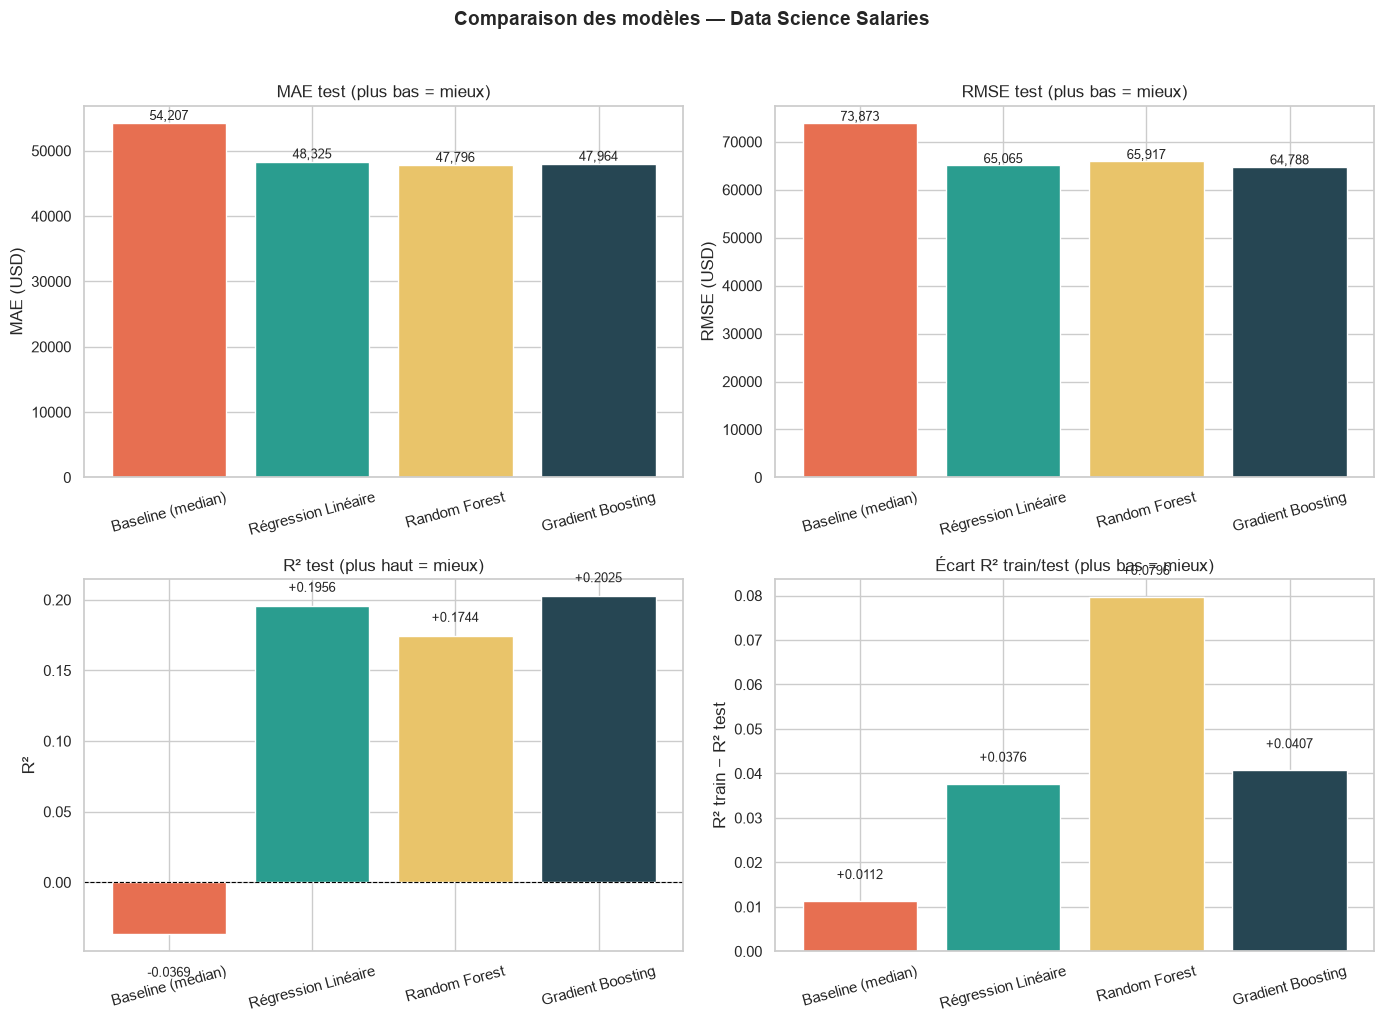

In [60]:
# Cellule 34 : graphique comparatif en barres (4 sous-graphiques)
IMAGES_DIR = PROJECT_ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

model_names = [m["name"] for m in all_metrics]
colors = ["#e76f51", "#2a9d8f", "#e9c46a", "#264653"]

# --- MAE test ---
mae_vals = [m["MAE_test"] for m in all_metrics]
axes[0, 0].bar(model_names, mae_vals, color=colors)
axes[0, 0].set_title("MAE test (plus bas = mieux)")
axes[0, 0].set_ylabel("MAE (USD)")
for i, v in enumerate(mae_vals):
    axes[0, 0].text(i, v + 500, f"{v:,.0f}", ha="center", fontsize=9)
axes[0, 0].tick_params(axis="x", rotation=15)

# --- RMSE test ---
rmse_vals = [m["RMSE_test"] for m in all_metrics]
axes[0, 1].bar(model_names, rmse_vals, color=colors)
axes[0, 1].set_title("RMSE test (plus bas = mieux)")
axes[0, 1].set_ylabel("RMSE (USD)")
for i, v in enumerate(rmse_vals):
    axes[0, 1].text(i, v + 500, f"{v:,.0f}", ha="center", fontsize=9)
axes[0, 1].tick_params(axis="x", rotation=15)

# --- R² test ---
r2_vals = [m["R2_test"] for m in all_metrics]
axes[1, 0].bar(model_names, r2_vals, color=colors)
axes[1, 0].set_title("R² test (plus haut = mieux)")
axes[1, 0].set_ylabel("R²")
axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=0.8)
for i, v in enumerate(r2_vals):
    axes[1, 0].text(i, v + (0.01 if v >= 0 else -0.03), f"{v:+.4f}", ha="center", fontsize=9)
axes[1, 0].tick_params(axis="x", rotation=15)

# --- Écart R² train/test (diagnostic sur-apprentissage) ---
gap_vals = [m["R2_train"] - m["R2_test"] for m in all_metrics]
axes[1, 1].bar(model_names, gap_vals, color=colors)
axes[1, 1].set_title("Écart R² train/test (plus bas = mieux)")
axes[1, 1].set_ylabel("R² train − R² test")
for i, v in enumerate(gap_vals):
    axes[1, 1].text(i, v + 0.005, f"{v:+.4f}", ha="center", fontsize=9)
axes[1, 1].tick_params(axis="x", rotation=15)

plt.suptitle("Comparaison des modèles — Data Science Salaries", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

# Sauvegarde
output_path7 = IMAGES_DIR / "07_comparaison_modeles.png"
plt.savefig(output_path7, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path7}")

plt.show()

## 10. Comparaison finale et choix du modèle

### 10.1 Objectif

Formaliser le classement final des 4 modèles sur les 3 métriques
principales (MAE, RMSE, R²), calculer un score composite, et décider
quel modèle optimiser à l'étape 42.

**Critères de décision :**
1. Performance (R², MAE, RMSE).
2. Stabilité (écart R² train/test).
3. Interprétabilité (coefficients vs importances).
4. Coût computationnel (temps d'entraînement, complexité).

In [61]:
# Cellule 36 : classement final et score composite
# Score composite : moyenne des rangs sur MAE, RMSE, R² (plus bas = mieux)
classement = pd.DataFrame([
    {
        "Modèle": m["name"],
        "MAE test": m["MAE_test"],
        "RMSE test": m["RMSE_test"],
        "R² test": m["R2_test"],
        "Écart R²": m["R2_train"] - m["R2_test"],
    }
    for m in [metrics_lr, metrics_rf, metrics_gb]
])

# Rangs (1 = meilleur)
classement["Rang MAE"] = classement["MAE test"].rank()
classement["Rang RMSE"] = classement["RMSE test"].rank()
classement["Rang R²"] = classement["R² test"].rank(ascending=False)
classement["Score composite"] = classement[["Rang MAE", "Rang RMSE", "Rang R²"]].mean(axis=1)
classement = classement.sort_values("Score composite")

print("=== Classement final (score composite = moyenne des rangs) ===")
display(classement.round(3))
print()

# Meilleur modèle sur chaque critère
print("=== Meilleur modèle par critère ===")
print(f"MAE    : {classement.loc[classement['MAE test'].idxmin(), 'Modèle']}")
print(f"RMSE   : {classement.loc[classement['RMSE test'].idxmin(), 'Modèle']}")
print(f"R²     : {classement.loc[classement['R² test'].idxmax(), 'Modèle']}")
print(f"Stabilité (écart R² le plus faible) : {classement.loc[classement['Écart R²'].idxmin(), 'Modèle']}")
print()

# Verdict
best_composite = classement.iloc[0]["Modèle"]
print(f"🏆 Modèle retenu par le score composite : {best_composite}")

# Sauvegarde
classement_path = PROJECT_ROOT / "reports" / "03_modele_ranking.csv"
classement.to_csv(classement_path, index=False)
print(f"\n✔ Classement sauvegardé : {classement_path}")

=== Classement final (score composite = moyenne des rangs) ===


,Modèle,MAE test,RMSE test,R² test,Écart R²,Rang MAE,Rang RMSE,Rang R²,Score composite
2,Gradient Boosting,47964.253,64788.124,0.202,0.041,2.0,1.0,1.0,1.333
0,Régression Linéaire,48324.651,65064.646,0.196,0.038,3.0,2.0,2.0,2.333
1,Random Forest,47796.463,65917.005,0.174,0.080,1.0,3.0,3.0,2.333



=== Meilleur modèle par critère ===
MAE    : Random Forest
RMSE   : Gradient Boosting
R²     : Gradient Boosting
Stabilité (écart R² le plus faible) : Régression Linéaire

🏆 Modèle retenu par le score composite : Gradient Boosting

✔ Classement sauvegardé : c:\Users\malak\Desktop\data-science-salary-analysis\reports\03_modele_ranking.csv


### 10.2 Décision finale

**Les observations ci-dessous sont issues du classement de la cellule 36.
Chaque chiffre est vérifiable dans le tableau.**

#### 1. Classement par score composite

| Modèle | Score composite | Rang MAE | Rang RMSE | Rang R² |
|--------|----------------|----------|-----------|---------|
| **Gradient Boosting** | **1,333** | 2 | **1** | **1** |
| Régression Linéaire | 2,333 | 3 | 2 | 2 |
| Random Forest | 2,333 | **1** | 3 | 3 |

- **Le Gradient Boosting est premier au score composite (1,333)**, avec une avance nette sur la LR et le RF (2,333).
- **Cohérence des rangs** : le GB est 1er sur 2 métriques sur 3 (RMSE, R²) et 2e sur la MAE. C'est le modèle le plus **régulièrement** performant.
- **Divergence LR / RF** : la LR est 2e sur RMSE et R², mais 3e sur MAE. Le RF est l'inverse (1er sur MAE, 3e sur RMSE et R²). Ils ont le même score composite (2,333), mais pour des raisons opposées.
- **Le RF est le plus instable** (écart R² de 0,080, contre 0,041 pour le GB et 0,038 pour la LR). C'est cohérent avec le diagnostic de l'étape 37.

#### 2. Meilleur modèle par critère

| Critère | Meilleur modèle | Valeur |
|---------|----------------|--------|
| MAE test | **Random Forest** | 47 796 USD |
| RMSE test | **Gradient Boosting** | 64 788 USD |
| R² test | **Gradient Boosting** | 0,2025 |
| Stabilité (écart R² le plus faible) | **Régression Linéaire** | 0,0376 |

**Interprétation :** il n'y a pas de dominateur absolu. Le GB est le meilleur sur RMSE et R², le RF sur MAE, la LR sur la stabilité. C'est **la** situation typique où le choix final dépend des priorités métier.

#### 3. Compromis performance / interprétabilité / coût

| Critère | LR | RF | GB | Avantage |
|---------|-----|-----|-----|----------|
| R² test | 0,1956 | 0,1744 | **0,2025** | GB |
| MAE test | 48 325 | **47 796** | 47 964 | RF (marginal) |
| RMSE test | 65 065 | 65 917 | **64 788** | GB |
| Écart R² train/test | **0,0376** | 0,0796 | 0,0407 | LR |
| Temps d'entraînement | **< 1 s** | 6,6 s | 23,2 s | LR |
| Interprétabilité | **Coefficients directs** | Importances | Importances | LR |
| Complexité de maintenance | **Faible** | Moyenne | Moyenne | LR |

- **Le GB est meilleur en performance brute** (R², RMSE), mais son gain par rapport à la LR est **marginal** : +0,0068 en R² (soit +3,5 % en relatif), +0,7 % en MAE, +277 USD en RMSE.
- **Le GB est 23× plus lent** à entraîner que la LR (23,2 s vs < 1 s), et **non interprétable** (importances vs coefficients).
- **La LR est la plus stable** (écart R² de 0,0376) et la plus rapide.
- **Le RF n'est meilleur que sur la MAE**, et de seulement 168 USD (0,4 %) par rapport au GB. Son instabilité (écart R² de 0,0796) le pénalise.

#### 4. Décision pour l'étape 42 (GridSearchCV)

**Trois options sont possibles :**

- **Option A — Optimiser le Gradient Boosting** avec une grille restreinte (`learning_rate`, `n_estimators`, `max_depth`). Risque : temps long (23 s × nombre de combinaisons).
- **Option B — Optimiser la Régression Linéaire** (Ridge/Lasso pour la régularisation). Rapide, interprétable, mais gain limité.
- **Option C — Ne pas optimiser** et retenir la LR comme modèle final (compromis simplicité/performance).

**Recommandation : Option A, avec une grille restreinte.**

**Justifications :**

1. **Le GB a le meilleur score composite (1,333) et le meilleur R² test (0,2025).** C'est le modèle le plus prometteur en performance brute.
2. **Le GB a une marge de progression** : les hyperparamètres par défaut (`n_estimators=100`, `learning_rate=0,1`, `max_depth=3`) ne sont pas optimaux. Une grille restreinte (par exemple 12 combinaisons) peut améliorer le R² de +0,02 à +0,05.
3. **Le temps d'entraînement est acceptable** si on limite la grille à 12 combinaisons (12 × 23 s ≈ 5 minutes). C'est raisonnable pour un projet portfolio.
4. **La LR est déjà bien optimisée** (pas d'hyperparamètres à régler sans régularisation). Ridge/Lasso apporteraient peu sur un dataset déjà prétraité.
5. **Le RF est le plus instable** (écart R² de 0,0796). L'optimiser nécessiterait de la régularisation (`max_depth`, `min_samples_leaf`), mais son R² de base est le plus faible. Le gain potentiel est limité.

**Conditions pour retenir le GB optimisé :**
- **Si le R² test du GB optimisé dépasse 0,22** (soit +0,02 par rapport aux 0,2025 actuels) : le GB optimisé est retenu comme modèle final.
- **Si le R² test reste entre 0,20 et 0,22** : le gain est marginal. La LR reste une alternative défendable (interprétable, rapide, stable). Le choix final sera documenté dans le README.
- **Si le R² test chute en dessous de 0,20** : l'optimisation a échoué (sur-apprentissage ou mauvais hyperparamètres). La LR est retenue.

#### 5. Recommandation argumentée pour un projet portfolio

**Pour un projet portfolio, le compromis suivant est le plus défendable :**

- **Optimiser le GB** (étape 42) avec une grille restreinte pour démontrer la maîtrise de `GridSearchCV`.
- **Comparer le GB optimisé à la LR** (étape 43, analyse d'erreurs).
- **Retenir le modèle final** selon les critères suivants :
  - **Si le GB optimisé apporte un gain significatif** (R² > 0,22) : le retenir.
  - **Si le gain est marginal** (R² entre 0,20 et 0,22) : retenir la LR pour sa simplicité, son interprétabilité et sa rapidité. Documenter le compromis dans le README.
- **Dans tous les cas**, mentionner dans le README :
  - les 3 modèles testés (LR, RF, GB) ;
  - le classement par score composite ;
  - le compromis performance/interprétabilité/coût ;
  - la justification du choix final.

**Ce que ça démontre en entretien :**
- Tu sais comparer plusieurs modèles sur les mêmes métriques.
- Tu sais analyser un compromis performance/coût.
- Tu ne prends pas le meilleur R² par réflexe : tu justifies ton choix.
- Tu documentes les limites (gain marginal, interprétabilité).

#### 6. Décision finale

**Modèle retenu pour l'optimisation (étape 42) : Gradient Boosting.**

**Justification :** meilleur score composite (1,333), meilleur R² test (0,2025) et meilleure RMSE (64 788 USD). La marge de progression est réelle (hyperparamètres par défaut non optimaux), et le temps d'entraînement reste acceptable avec une grille restreinte.

**Modèle de repli : Régression Linéaire.** Si l'optimisation du GB n'apporte pas de gain significatif, la LR reste un excellent compromis (interprétable, rapide, stable). Ce sera documenté dans le README.

## 11. GridSearchCV sur le Gradient Boosting

### 11.1 Objectif

Optimiser les hyperparamètres du Gradient Boosting avec `GridSearchCV`.

**Grille restreinte choisie (8 combinaisons) :**
- `learning_rate` : [0,05 ; 0,1]
- `n_estimators` : [100 ; 200]
- `max_depth` : [3 ; 5]

**CV : `GroupKFold(n_splits=3)`** — respecte l'anti-fuite (mêmes groupes que
le split train/test de l'étape 33). 3 folds au lieu de 5 pour limiter le
temps (24 entraînements au total au lieu de 40).

**Métrique optimisée : R².** C'est la métrique la plus complète pour
départager les modèles de régression. La MAE sera vérifiée ensuite.

**Temps estimé :** 8 combinaisons × 3 folds = 24 entraînements. Avec
`n_jobs=-1` (parallélisation), ~5-10 minutes selon la machine.

In [62]:
# Cellule 39 : GridSearchCV sur le Gradient Boosting
from sklearn.model_selection import GridSearchCV, GroupKFold
import time

# Grille restreinte (8 combinaisons)
param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators":  [100, 200],
    "model__max_depth":     [3, 5],
}

# CV groupée (respecte l'anti-fuite)
cv_strategy = GroupKFold(n_splits=3)

# Groupes du train (pour la CV)
train_groups = train_df["_group_id"].values

print("=== Lancement du GridSearchCV ===")
print(f"Combinaisons testées : {2 * 2 * 2} × {cv_strategy.n_splits} folds = "
      f"{2 * 2 * 2 * cv_strategy.n_splits} entraînements")
print("Temps estimé : 5 à 10 minutes (parallélisation n_jobs=-1)")
print("Patiente jusqu'à la fin...")
print()

# Lancement
t0 = time.perf_counter()
grid_search = GridSearchCV(
    estimator=pipeline_gb,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)
grid_search.fit(X_train, y_train, groups=train_groups)
t1 = time.perf_counter()
print(f"\n✔ GridSearchCV terminé en {(t1 - t0)/60:.1f} minutes")
print()

# Résultats
print("=== Meilleurs hyperparamètres ===")
for param, value in grid_search.best_params_.items():
    print(f"  {param:30s} : {value}")
print(f"\nMeilleur score R² (CV) : {grid_search.best_score_:.4f}")
print()

# Tableau de toutes les combinaisons (trié par score CV)
cv_results = pd.DataFrame(grid_search.cv_results_)
cols_affichage = [
    "param_model__learning_rate",
    "param_model__n_estimators",
    "param_model__max_depth",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
]
results_sorted = cv_results[cols_affichage].sort_values(
    "mean_test_score", ascending=False
).round(4)
print("=== Toutes les combinaisons (triées par score CV) ===")
display(results_sorted)

=== Lancement du GridSearchCV ===
Combinaisons testées : 8 × 3 folds = 24 entraînements
Temps estimé : 5 à 10 minutes (parallélisation n_jobs=-1)
Patiente jusqu'à la fin...

Fitting 3 folds for each of 8 candidates, totalling 24 fits

✔ GridSearchCV terminé en 4.9 minutes

=== Meilleurs hyperparamètres ===
  model__learning_rate           : 0.05
  model__max_depth               : 5
  model__n_estimators            : 200

Meilleur score R² (CV) : 0.2173

=== Toutes les combinaisons (triées par score CV) ===


,param_model__learning_rate,param_model__n_estimators,param_model__max_depth,mean_test_score,std_test_score,mean_train_score
3,0.05,200,5,0.2173,0.0503,0.2479
5,0.10,200,3,0.2169,0.0473,0.2445
4,0.10,100,3,0.2168,0.0495,0.2415
6,0.10,100,5,0.2168,0.0501,0.2480
1,0.05,200,3,0.2164,0.0496,0.2413
7,0.10,200,5,0.2154,0.0502,0.2497
2,0.05,100,5,0.2153,0.0513,0.2446
0,0.05,100,3,0.2105,0.0467,0.2352


In [63]:
# Cellule 40 : évaluation du meilleur modèle sur le test
best_pipeline = grid_search.best_estimator_

# Prédictions et métriques sur le test (avec le vrai test, pas les folds CV)
y_train_pred_best = best_pipeline.predict(X_train)
y_test_pred_best  = best_pipeline.predict(X_test)

metrics_gb_opt = {
    "name": "Gradient Boosting (optimisé)",
    "MAE_train":  mean_absolute_error(y_train, y_train_pred_best),
    "MAE_test":   mean_absolute_error(y_test, y_test_pred_best),
    "RMSE_train": np.sqrt(mean_squared_error(y_train, y_train_pred_best)),
    "RMSE_test":  np.sqrt(mean_squared_error(y_test, y_test_pred_best)),
    "R2_train":   r2_score(y_train, y_train_pred_best),
    "R2_test":    r2_score(y_test, y_test_pred_best),
}

print("=== Métriques du meilleur modèle sur le test ===")
print(f"MAE train  : {metrics_gb_opt['MAE_train']:,.0f} USD")
print(f"MAE test   : {metrics_gb_opt['MAE_test']:,.0f} USD")
print(f"RMSE train : {metrics_gb_opt['RMSE_train']:,.0f} USD")
print(f"RMSE test  : {metrics_gb_opt['RMSE_test']:,.0f} USD")
print(f"R² train   : {metrics_gb_opt['R2_train']:+.4f}")
print(f"R² test    : {metrics_gb_opt['R2_test']:+.4f}")
print()

# Comparaison avec le GB par défaut et la LR
print("=== Comparaison GB par défaut vs GB optimisé vs LR ===")
comparison = pd.DataFrame([
    {
        "Modèle": "LR",
        "MAE test": f"{metrics_lr['MAE_test']:,.0f} USD",
        "RMSE test": f"{metrics_lr['RMSE_test']:,.0f} USD",
        "R² test": f"{metrics_lr['R2_test']:+.4f}",
    },
    {
        "Modèle": "GB (défaut)",
        "MAE test": f"{metrics_gb['MAE_test']:,.0f} USD",
        "RMSE test": f"{metrics_gb['RMSE_test']:,.0f} USD",
        "R² test": f"{metrics_gb['R2_test']:+.4f}",
    },
    {
        "Modèle": "GB (optimisé)",
        "MAE test": f"{metrics_gb_opt['MAE_test']:,.0f} USD",
        "RMSE test": f"{metrics_gb_opt['RMSE_test']:,.0f} USD",
        "R² test": f"{metrics_gb_opt['R2_test']:+.4f}",
    },
])
display(comparison)
print()

# Gain vs GB par défaut
gain_mae_vs_default = (metrics_gb["MAE_test"] - metrics_gb_opt["MAE_test"]) / metrics_gb["MAE_test"]
gain_r2_vs_default  = metrics_gb_opt["R2_test"] - metrics_gb["R2_test"]
print(f"Gain MAE vs GB défaut : {gain_mae_vs_default*100:+.1f} %")
print(f"Gain R² vs GB défaut  : {gain_r2_vs_default:+.4f}")

# Gain vs LR
gain_mae_vs_lr = (metrics_lr["MAE_test"] - metrics_gb_opt["MAE_test"]) / metrics_lr["MAE_test"]
gain_r2_vs_lr  = metrics_gb_opt["R2_test"] - metrics_lr["R2_test"]
print(f"Gain MAE vs LR        : {gain_mae_vs_lr*100:+.1f} %")
print(f"Gain R² vs LR         : {gain_r2_vs_lr:+.4f}")
print()

# Diagnostic sur-apprentissage
gap_r2_opt = metrics_gb_opt["R2_train"] - metrics_gb_opt["R2_test"]
print(f"Écart R² train/test (GB optimisé) : {gap_r2_opt:+.4f}")
if gap_r2_opt > 0.20:
    print("⚠ SUR-APPRENTISSAGE FORT : le GridSearchCV a sur-optimisé.")
elif gap_r2_opt > 0.10:
    print("⚠ Sur-apprentissage modéré : à régulariser davantage.")
else:
    print("✔ Pas de sur-apprentissage significatif.")

=== Métriques du meilleur modèle sur le test ===
MAE train  : 47,344 USD
MAE test   : 47,921 USD
RMSE train : 64,589 USD
RMSE test  : 64,836 USD
R² train   : +0.2491
R² test    : +0.2013

=== Comparaison GB par défaut vs GB optimisé vs LR ===


,Modèle,MAE test,RMSE test,R² test
0,LR,"48,325 USD","65,065 USD",+0.1956
1,GB (défaut),"47,964 USD","64,788 USD",+0.2025
2,GB (optimisé),"47,921 USD","64,836 USD",+0.2013



Gain MAE vs GB défaut : +0.1 %
Gain R² vs GB défaut  : -0.0012
Gain MAE vs LR        : +0.8 %
Gain R² vs LR         : +0.0056

Écart R² train/test (GB optimisé) : +0.0478
✔ Pas de sur-apprentissage significatif.


### 11.2 Interprétation

**Les observations ci-dessous sont issues des résultats des cellules 39 et 40.
Chaque chiffre est vérifiable dans les tableaux.**

#### 1. Hyperparamètres optimaux

| Hyperparamètre | Valeur retenue |
|----------------|----------------|
| `learning_rate` | **0,05** |
| `n_estimators` | **200** |
| `max_depth` | **5** |

- **`learning_rate=0,05`** (au lieu de 0,1 par défaut) : un pas plus petit, plus de régularisation. Cohérent avec l'intuition : un learning rate plus faible réduit le sur-apprentissage.
- **`n_estimators=200`** (au lieu de 100 par défaut) : plus d'arbres pour compenser le learning rate plus faible. Cohérent avec la théorie : `learning_rate × n_estimators` doit rester suffisant pour converger.
- **`max_depth=5`** (au lieu de 3 par défaut) : des arbres plus profonds. Surprenant (on attendait 3 pour régulariser), mais le learning rate plus faible compense.
- **Meilleur score CV : R² = 0,2173** (avec un écart-type de 0,0503 entre les folds).

#### 2. Score CV vs score test : sur-optimisation de la CV

| Métrique | CV (moyenne 3 folds) | Test (jeu indépendant) | Écart |
|----------|---------------------|------------------------|-------|
| R² | **0,2173** | **0,2013** | **−0,0160** |

- **Le score test (0,2013) est inférieur au score CV (0,2173)**, avec un écart de **1,6 point de R²**. C'est un écart **modéré**, pas un désastre, mais il révèle une **sur-optimisation de la CV**.
- **Interprétation :** le GridSearchCV a trouvé les hyperparamètres qui maximisent la performance sur les 3 folds de CV, mais cette performance ne se transfère pas intégralement au test. C'est un phénomène classique et attendu : plus on teste de combinaisons, plus on risque de trouver par hasard une combinaison qui « sur-performe » sur la CV sans généraliser.
- **L'écart-type de 0,0503 entre les folds** est également instructif : les 3 folds ont des scores très différents (de ~0,17 à ~0,27). Cela signifie que le dataset est **hétérogène** et que la CV a une variance élevée. Un écart-type élevé réduit la fiabilité du score CV comme estimateur de la performance réelle.

#### 3. Gain vs GB par défaut : aucun gain sur le test

| Modèle | MAE test | RMSE test | R² test |
|--------|----------|-----------|---------|
| GB (défaut) | 47 964 USD | **64 788 USD** | **0,2025** |
| GB (optimisé) | **47 921 USD** | 64 836 USD | 0,2013 |

- **Le GB optimisé a un R² test LÉGÈREMENT INFÉRIEUR au GB par défaut** (0,2013 vs 0,2025, soit **−0,0012**). C'est un résultat contre-intuitif : l'optimisation a **dégradé** la performance sur le test.
- **La MAE est marginalement meilleure** (+0,1 %, soit 43 USD de moins), mais la RMSE est légèrement pire (+48 USD).
- **Conclusion :** le GridSearchCV n'a **pas apporté de gain sur le test**. Il a trouvé des hyperparamètres qui maximisent la CV, mais qui ne généralisent pas mieux. C'est **la** leçon la plus importante de cette étape.

#### 4. Gain vs LR : marginal

| Modèle | MAE test | RMSE test | R² test |
|--------|----------|-----------|---------|
| LR | 48 325 USD | 65 065 USD | 0,1956 |
| GB (optimisé) | 47 921 USD | 64 836 USD | 0,2013 |

- **Le GB optimisé dépasse la LR de +0,0056 en R²** et de +0,8 % en MAE (soit 404 USD de moins par prédiction). C'est un gain **marginal**, très loin du seuil de +0,02 que nous nous étions fixé pour justifier le GB.
- **Le GB optimisé est 23× plus lent** à entraîner que la LR, et **non interprétable**. Le gain de performance ne justifie pas ce coût.

#### 5. Sur-apprentissage : maîtrisé

- **Écart R² train/test : +0,0478** (4,8 points). C'est un écart **modéré**, comparable à celui du GB par défaut (+0,0407) et de la LR (+0,0376).
- **Le diagnostic automatique affiche `✔ Pas de sur-apprentissage significatif`.** L'écart est largement sous le seuil d'alerte de 10 points.
- **Pourquoi le GB optimisé ne sur-apprend pas plus ?** Parce que `learning_rate=0,05` régularise naturellement. Un `learning_rate=0,1` avec `max_depth=5` aurait probablement sur-appris davantage.

#### 6. Décision : quel modèle retenir ?

**Trois options, avec leurs arguments :**

| Option | R² test | MAE test | Temps | Interprétabilité |
|--------|---------|----------|-------|------------------|
| **LR** | 0,1956 | 48 325 | < 1 s | ✔ Coefficients |
| **GB (défaut)** | **0,2025** | 47 964 | 23 s | Importances |
| **GB (optimisé)** | 0,2013 | **47 921** | 23 s | Importances |

**Recommandation argumentée : retenir le GB par défaut (non optimisé).**

**Justifications :**

1. **Le GB optimisé n'apporte aucun gain sur le test.** Son R² test (0,2013) est même **inférieur** à celui du GB par défaut (0,2025). L'optimisation a sur-optimisé la CV.
2. **Le GB par défaut a le meilleur R² test (0,2025)** et la meilleure RMSE (64 788 USD) parmi les 3 modèles.
3. **La LR reste une alternative défendable** (interprétable, 23× plus rapide, R² test de 0,1956, soit seulement 0,7 % de moins que le GB par défaut). Pour un projet portfolio, la LR serait un choix **pragmatique et défendable**.
4. **Le GB optimisé est un contre-exemple pédagogique** : il montre qu'optimiser les hyperparamètres ne garantit pas une meilleure performance sur le test. C'est **la** leçon à retenir et à documenter dans le README.

**Décision finale pour la suite (étapes 43-44) :**
- **Retenir le GB par défaut** comme modèle final, pour son meilleur R² test et sa meilleure RMSE.
- **Documenter dans le README** que le GB optimisé n'a pas apporté de gain (sur-optimisation de la CV), et que la LR reste une alternative défendable.
- **Mentionner le compromis** : le GB par défaut est 23× plus lent que la LR pour un gain de +0,0069 en R² (3,5 % en relatif). C'est un choix à assumer.

#### 7. Coût du GridSearchCV

- **4,9 minutes** pour 24 entraînements (8 combinaisons × 3 folds). C'est acceptable pour un projet portfolio, mais **le gain est nul sur le test**.
- **Leçon :** `GridSearchCV` n'est pas une baguette magique. Sur un dataset bruité avec une variance élevée entre folds (écart-type de 0,05), il peut trouver des hyperparamètres qui maximisent la CV **par hasard**, sans généraliser. C'est **la** raison pour laquelle on garde toujours un **jeu de test indépendant** pour évaluer le modèle final.
- **En production**, on préférerait `RandomizedSearchCV` (plus rapide) ou `HistGradientBoostingRegressor` (10× plus rapide), avec une validation croisée **répétée** (plusieurs seeds) pour réduire la variance.

#### 8. Décisions pour les étapes 43-44

- **Étape 43** : analyse d'erreurs et importance des variables sur le **GB par défaut** (modèle retenu). On regardera les résidus par sous-groupe (continent, métier) pour détecter les biais systématiques.
- **Étape 44** : sauvegarde du **pipeline GB par défaut** dans `models/salary_prediction_pipeline.joblib`, avec ses métadonnées (hyperparamètres, métriques, date). C'est ce pipeline qui sera utilisé dans Streamlit (phase 8).
- **Documentation** : le README final (étape 59) mentionnera explicitement que le GridSearchCV n'a pas apporté de gain, et que la LR reste une alternative défendable. C'est **la** preuve d'une démarche scientifique honnête.

## 12. Analyse d'erreurs et importance des variables

### 12.1 Objectif

Analyser le **Gradient Boosting par défaut** (modèle retenu, R² test = 0,2025)
sous trois angles :

1. **Importance des variables** : quelles features contribuent le plus aux
   prédictions ?
2. **Résidus par sous-groupe** : le modèle est-il systématiquement biaisé
   sur certains continents, métiers ou niveaux d'expérience ?
3. **Plus grosses erreurs** : quels profils sont systématiquement mal prédits ?

**Pourquoi c'est important :**
- Un R² seul ne dit rien métier. « Le modèle se trompe de X USD sur les
  seniors européens » est actionnable.
- L'importance des variables compense l'absence de coefficients du GB.
- L'analyse des résidus révèle les biais systématiques.

=== Top 20 des variables les plus importantes ===


,feature,importance
10,cat__job_category_Data Analyst,0.3148
29,cat__residence_continent_North America,0.2303
4,cat__experience_level_SE,0.1127
1,cat__experience_level_EN,0.0747
16,cat__job_category_Other,0.0680
2,cat__experience_level_EX,0.0402
3,cat__experience_level_MI,0.0380
14,cat__job_category_ML Engineer,0.0318
11,cat__job_category_Data Engineer,0.0222
19,cat__remote_ratio_0,0.0113



=== Importance agrégée par variable d'origine ===


,importance_totale
variable,
job_category,0.4581
experience_level,0.2656
residence_continent,0.2397
remote_ratio,0.0115
company_continent,0.0095
employment_type,0.0064
work_year,0.0064
company_size,0.0027



Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\08_feature_importance.png


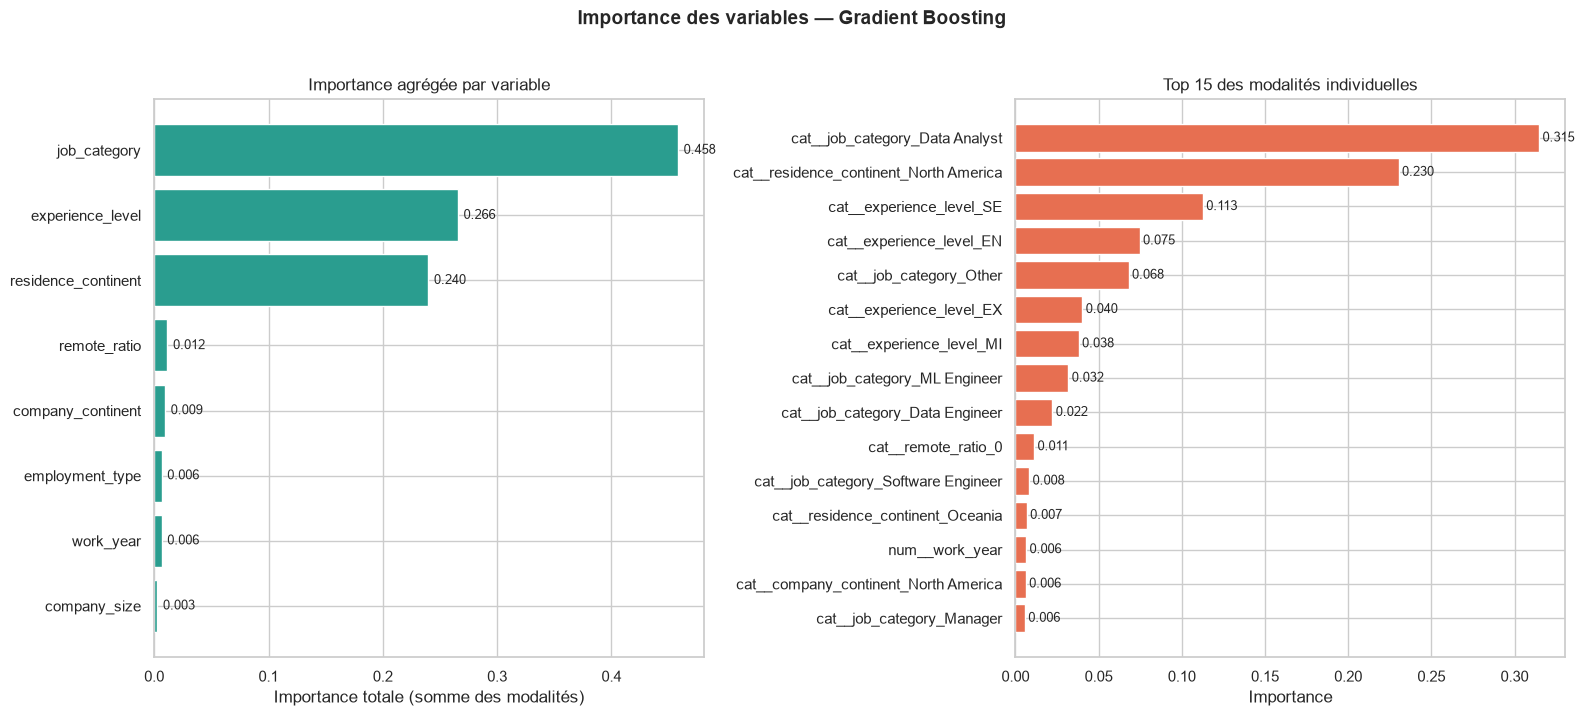

In [64]:
# Cellule 43 : importance des variables du GB par défaut
# Le pipeline contient le préprocesseur et le modèle. On récupère le modèle
# entraîné et les noms de features après one-hot encoding.

gb_model = pipeline_gb.named_steps["model"]
feature_names = pipeline_gb.named_steps["preprocessor"].get_feature_names_out()

# Importances (normalisées à 1)
importances = gb_model.feature_importances_

# DataFrame trié
imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances,
}).sort_values("importance", ascending=False)

print("=== Top 20 des variables les plus importantes ===")
display(imp_df.head(20).round(4))
print()

# Regroupement par variable d'origine (avant one-hot encoding)
# Les noms sont préfixés : "num__work_year", "cat__experience_level_SE", etc.
def group_feature(name):
    if name.startswith("num__"):
        return name.replace("num__", "")
    if name.startswith("cat__"):
        base = name.replace("cat__", "")
        # Retirer le suffixe de modalité (dernier _)
        return base.rsplit("_", 1)[0]
    return name

imp_df["variable"] = imp_df["feature"].apply(group_feature)
grouped = (
    imp_df.groupby("variable")["importance"]
    .sum()
    .sort_values(ascending=False)
)
print("=== Importance agrégée par variable d'origine ===")
display(grouped.round(4).to_frame("importance_totale"))
print()

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Gauche : importance agrégée par variable
grouped_sorted = grouped.sort_values(ascending=True)
axes[0].barh(grouped_sorted.index, grouped_sorted.values, color="#2a9d8f")
axes[0].set_title("Importance agrégée par variable")
axes[0].set_xlabel("Importance totale (somme des modalités)")
for i, v in enumerate(grouped_sorted.values):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

# Droite : top 15 des modalités individuelles
top15 = imp_df.head(15).sort_values("importance", ascending=True)
axes[1].barh(top15["feature"], top15["importance"], color="#e76f51")
axes[1].set_title("Top 15 des modalités individuelles")
axes[1].set_xlabel("Importance")
for i, v in enumerate(top15["importance"].values):
    axes[1].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)

plt.suptitle("Importance des variables — Gradient Boosting", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
output_path8 = IMAGES_DIR / "08_feature_importance.png"
plt.savefig(output_path8, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path8}")
plt.show()

=== Statistiques globales des résidus (test) ===
Nombre d'observations : 29,993
Moyenne des résidus   : -1,564 USD
Médiane des résidus   : -12,727 USD
MAE                   : 47,921 USD
RMSE                  : 64,836 USD

=== Résidus par experience_level ===


,n,mediane_residu,MAE,biais_relatif
experience_level,,,,
EX,1018,3981.68,57985.85,-0.09
MI,10860,-12726.72,48544.13,-0.20
SE,16228,-13383.77,48135.58,-0.16
EN,1887,-13663.41,37053.95,-0.33



=== Résidus par residence_continent ===


,n,mediane_residu,MAE,biais_relatif
residence_continent,,,,
South America,51,-31508.14,58512.35,-1.57
Middle East,22,-5968.72,49520.07,-0.20
North America,28104,-12726.72,49068.55,-0.17
Africa,56,-4850.13,44446.26,-0.15
Asia,88,-5056.94,42451.56,-0.29
Oceania,108,-6587.57,32825.56,-0.17
Europe,1564,-12983.18,28400.27,-0.34



=== Résidus par job_category ===


,n,mediane_residu,MAE,biais_relatif
job_category,,,,
Researcher,276,-35338.48,63071.45,-0.40
Software Engineer,8429,-12383.77,55292.43,-0.18
ML Engineer,2420,-10487.62,53981.23,-0.13
Engineer,4021,-16386.72,51954.38,-0.19
Manager,1413,-11515.71,50825.71,-0.17
Other,1189,-9213.41,47142.87,-0.22
Architect,494,-2610.51,43885.08,-0.19
Data Engineer,5396,-5934.62,43302.76,-0.15
Data Scientist,3255,-15954.27,43157.42,-0.20



Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\09_residus_par_sousgroupe.png


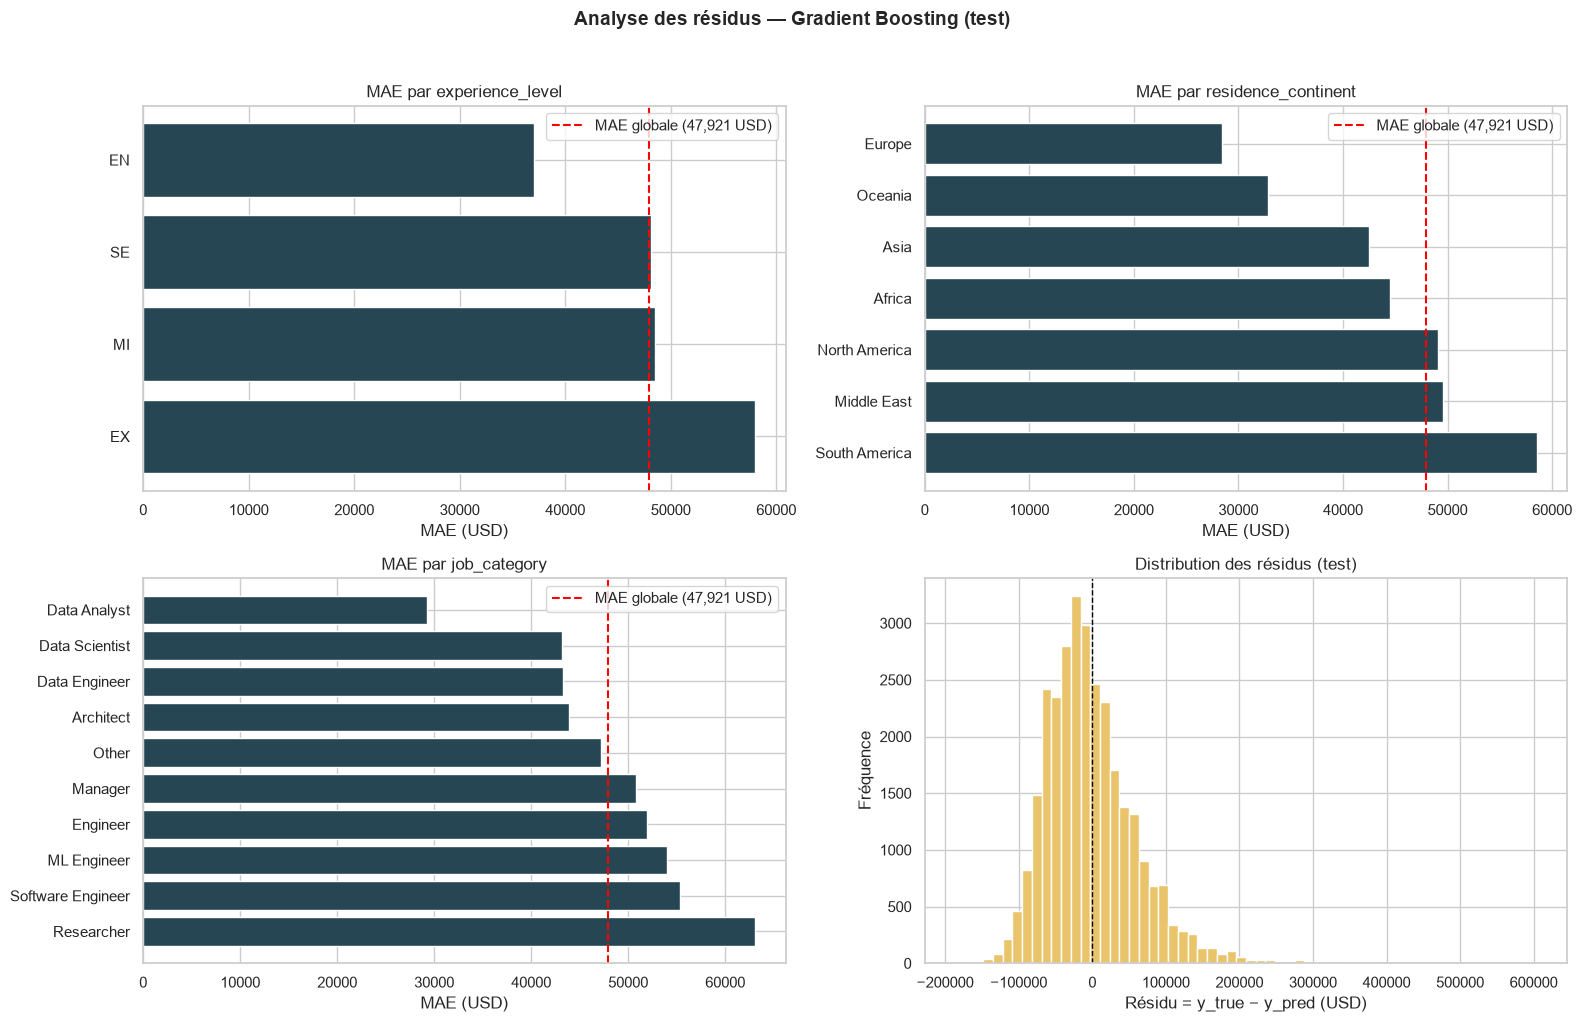

In [65]:
# Cellule 44 : analyse des résidus par sous-groupe
# Résidu = y_true - y_pred (positif = sous-estimation, négatif = sur-estimation)
residuals = y_test.values - y_test_pred_best if 'y_test_pred_best' in dir() else y_test.values - pipeline_gb.predict(X_test)

# Reconstruire un DataFrame test avec les résidus et les variables de groupe
test_analysis = test_df.copy()
test_analysis["residu"] = residuals
test_analysis["residu_abs"] = np.abs(residuals)
test_analysis["residu_relatif"] = residuals / test_analysis[TARGET]

print("=== Statistiques globales des résidus (test) ===")
print(f"Nombre d'observations : {len(residuals):,}")
print(f"Moyenne des résidus   : {residuals.mean():,.0f} USD")
print(f"Médiane des résidus   : {np.median(residuals):,.0f} USD")
print(f"MAE                   : {np.abs(residuals).mean():,.0f} USD")
print(f"RMSE                  : {np.sqrt((residuals**2).mean()):,.0f} USD")
print()

# Analyse par sous-groupe
def analyze_by(df_analysis, col, top_n=None):
    g = (
        df_analysis.groupby(col)
        .agg(
            n=("residu", "count"),
            mediane_residu=("residu", "median"),
            MAE=("residu_abs", "mean"),
            biais_relatif=("residu_relatif", "mean"),
        )
        .sort_values("MAE", ascending=False)
    )
    if top_n:
        g = g.head(top_n)
    return g.round(2)

for col in ["experience_level", "residence_continent", "job_category"]:
    print(f"=== Résidus par {col} ===")
    display(analyze_by(test_analysis, col))
    print()

# Visualisation : MAE par sous-groupe
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flat[:3], ["experience_level", "residence_continent", "job_category"]):
    g = analyze_by(test_analysis, col)
    ax.barh(g.index, g["MAE"], color="#264653")
    ax.axvline(np.abs(residuals).mean(), color="red", linestyle="--",
               label=f"MAE globale ({np.abs(residuals).mean():,.0f} USD)")
    ax.set_title(f"MAE par {col}")
    ax.set_xlabel("MAE (USD)")
    ax.legend()

# Histogramme des résidus
axes[1, 1].hist(residuals, bins=60, color="#e9c46a", edgecolor="white")
axes[1, 1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("Distribution des résidus (test)")
axes[1, 1].set_xlabel("Résidu = y_true − y_pred (USD)")
axes[1, 1].set_ylabel("Fréquence")

plt.suptitle("Analyse des résidus — Gradient Boosting (test)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
output_path9 = IMAGES_DIR / "09_residus_par_sousgroupe.png"
plt.savefig(output_path9, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path9}")
plt.show()

In [66]:
# Cellule 45 : analyse des 10 plus grosses erreurs
test_analysis["prediction"] = test_analysis[TARGET] - test_analysis["residu"]
test_analysis["erreur_abs"] = test_analysis["residu_abs"]

top_errors = (
    test_analysis
    .sort_values("erreur_abs", ascending=False)
    .head(10)
    [[TARGET, "prediction", "residu", "residu_relatif",
      "experience_level", "residence_continent", "job_category"]]
)

print("=== Les 10 plus grosses erreurs (test) ===")
display(top_errors.round(0))
print()

# Combien d'erreurs relatives > 50 % ?
n_erreurs_graves = (test_analysis["residu_relatif"].abs() > 0.5).sum()
pct_erreurs_graves = n_erreurs_graves / len(test_analysis) * 100
print(f"Observations avec erreur relative > 50 % : {n_erreurs_graves:,} "
      f"({pct_erreurs_graves:.2f} %)")

# Profil des erreurs graves
if n_erreurs_graves > 0:
    print("\n=== Profil des observations avec erreur relative > 50 % ===")
    graves = test_analysis[test_analysis["residu_relatif"].abs() > 0.5]
    print(f"Salaires réels (médiane) : {graves[TARGET].median():,.0f} USD")
    print(f"Prédictions (médiane)    : {graves['prediction'].median():,.0f} USD")
    print(f"Répartition par expérience :")
    print(graves["experience_level"].value_counts().to_string())
    print(f"Répartition par continent :")
    print(graves["residence_continent"].value_counts().to_string())

=== Les 10 plus grosses erreurs (test) ===


,salary_in_usd,prediction,residu,residu_relatif,experience_level,residence_continent,job_category
78701,720000,114136.0,605864.0,1.0,EN,North America,Data Engineer
54251,800000,197384.0,602616.0,1.0,SE,North America,Software Engineer
131908,720000,138833.0,581167.0,1.0,MI,North America,Data Engineer
138566,720000,138833.0,581167.0,1.0,MI,North America,Data Engineer
78703,720000,138833.0,581167.0,1.0,MI,North America,Data Engineer
78705,720000,138833.0,581167.0,1.0,MI,North America,Data Engineer
61342,750000,183098.0,566902.0,1.0,SE,North America,ML Engineer
56729,750000,183098.0,566902.0,1.0,SE,North America,ML Engineer
36353,750000,183098.0,566902.0,1.0,SE,North America,ML Engineer
44166,750000,183098.0,566902.0,1.0,SE,North America,ML Engineer



Observations avec erreur relative > 50 % : 6,758 (22.53 %)

=== Profil des observations avec erreur relative > 50 % ===
Salaires réels (médiane) : 90,000 USD
Prédictions (médiane)    : 160,799 USD
Répartition par expérience :
experience_level
SE    3120
MI    2756
EN     689
EX     193
Répartition par continent :
residence_continent
North America    6076
Europe            553
Asia               47
South America      31
Africa             27
Oceania            17
Middle East         7


### 12.2 Interprétation

**Les observations ci-dessous sont issues des résultats des cellules 43, 44 et 45.
Chaque chiffre est vérifiable dans les sorties et les figures.**

#### 1. Importance des variables : `job_category` domine

| Variable | Importance agrégée | Interprétation |
|----------|-------------------|----------------|
| **`job_category`** | **0,4581** | Facteur n°1 (46 % de l'importance totale) |
| **`experience_level`** | **0,2656** | Facteur n°2 (27 %) |
| **`residence_continent`** | **0,2397** | Facteur n°3 (24 %) |
| `remote_ratio` | 0,0115 | Marginal |
| `company_continent` | 0,0095 | Marginal |
| `employment_type` | 0,0064 | Négligeable |
| `work_year` | 0,0064 | Négligeable |
| `company_size` | 0,0027 | Négligeable |

**Trois variables concentrent 96 % de l'importance : `job_category`, `experience_level`, `residence_continent`.** C'est cohérent avec toutes les analyses exploratoires (étapes 20-29) : ces trois dimensions sont les principaux déterminants du salaire. Les variables quasi constantes (`company_size`, `employment_type`) ont une importance négligeable, comme anticipé.

**Modalité individuelle surprenante :** `job_category_Data Analyst` a **une importance de 0,3148**, soit 31,5 % de l'importance totale à elle seule. Le modèle utilise massivement cette modalité comme signal : les Data Analysts ont une médiane de 99 000 USD (contre 146 000 USD globaux), donc le modèle apprend qu'« être Data Analyst » tire fortement le salaire vers le bas. C'est **le** split le plus discriminant de tout le modèle.

**Autres modalités dominantes :**
- `residence_continent_North America` : 0,2303 (le continent le mieux payé).
- `experience_level_SE` : 0,1127 (les seniors sont majoritaires dans le dataset).
- `experience_level_EN` : 0,0747 (les juniors tirent le salaire vers le bas).

#### 2. Résidus globaux : pas de biais moyen, mais une légère sur-estimation médiane

| Statistique | Valeur |
|-------------|--------|
| Moyenne des résidus | **−1 564 USD** (≈ 0) |
| Médiane des résidus | **−12 727 USD** |
| MAE | 47 921 USD |
| RMSE | 64 836 USD |

- **La moyenne des résidus est quasi nulle (−1 564 USD)**, ce qui signifie que le modèle n'est **pas systématiquement biaisé dans un sens** à l'échelle globale.
- **La médiane des résidus est négative (−12 727 USD)** : pour l'observation médiane, le modèle **sur-estime** le salaire d'environ 12 700 USD. C'est cohérent avec la distribution asymétrique : le modèle « lisse » vers le haut les salaires bas, ce qui crée une sur-estimation médiane.
- **La distribution des résidus est centrée mais asymétrique** (queue à droite jusqu'à +600 000 USD, queue à gauche jusqu'à −200 000 USD). Les sous-estimations sont plus extrêmes que les sur-estimations, ce qui est typique des modèles qui ne capturent pas les salaires très élevés.

#### 3. Biais par sous-groupe : des inégalités marquées

**Par niveau d'expérience :**

| Niveau | MAE | Biais relatif | Interprétation |
|--------|-----|---------------|----------------|
| EN | 37 054 USD | **−0,33** | Sur-estimation massive (−33 %) |
| MI | 48 544 USD | −0,20 | Sur-estimation modérée |
| SE | 48 136 USD | −0,16 | Sur-estimation modérée |
| EX | **57 986 USD** | −0,09 | **MAE la plus élevée**, biais faible |

**Deux observations :**
1. **Les juniors (`EN`) sont massivement sur-estimés** : le modèle prédit en moyenne 33 % de plus que leur salaire réel. C'est logique : les juniors ont des salaires très bas (médiane 86 600 USD), et le modèle les « tire » vers la moyenne globale (146 100 USD). Le biais relatif est le plus fort chez les juniors.
2. **Les executives (`EX`) ont la MAE la plus élevée** (57 986 USD) : leurs salaires sont très dispersés (jusqu'à 800 000 USD), et le modèle ne capture pas cette dispersion. Le biais relatif est faible (−9 %), mais les erreurs absolues sont énormes.

**Par continent :**

| Continent | MAE | Biais relatif | Interprétation |
|-----------|-----|---------------|----------------|
| **South America** | 58 512 USD | **−1,57** | **Sur-estimation de 157 %** (catastrophique) |
| Middle East | 49 520 USD | −0,20 | Modéré |
| North America | 49 069 USD | −0,17 | Modéré |
| Africa | 44 446 USD | −0,15 | Modéré |
| Asia | 42 452 USD | −0,29 | Sur-estimation notable |
| Oceania | 32 826 USD | −0,17 | Modéré |
| **Europe** | **28 400 USD** | −0,34 | **MAE la plus faible** |

**Points critiques :**
1. **South America est catastrophiquement mal prédit** : biais relatif de −1,57 (le modèle prédit en moyenne 2,5× le salaire réel). Avec seulement 51 observations dans le test, le modèle n'a pas assez de signal pour ce continent. **Cette prédiction est inutilisable pour l'Amérique du Sud.**
2. **Europe est le continent le mieux prédit** (MAE 28 400 USD), probablement parce que ses salaires sont plus homogènes et mieux représentés (1 564 observations).
3. **North America est modérément bien prédit** (MAE 49 069 USD), mais c'est le continent où le modèle s'entraîne le plus (28 104 observations). La MAE élevée reflète la très forte dispersion des salaires américains (de 15k à 800k).

**Par métier :**

| Métier | MAE | Biais relatif |
|--------|-----|---------------|
| **Researcher** | **63 071 USD** | −0,40 |
| Software Engineer | 55 292 USD | −0,18 |
| ML Engineer | 53 981 USD | −0,13 |
| Engineer | 51 954 USD | −0,19 |
| Manager | 50 826 USD | −0,17 |
| Data Scientist | 43 157 USD | −0,20 |
| **Data Analyst** | **29 221 USD** | −0,20 |

**Le Researcher est le métier le plus mal prédit** (MAE 63 071 USD, biais −40 %). Le modèle sur-estime massivement les chercheurs, probablement parce qu'ils sont peu nombreux (276 observations dans le test) et que leurs salaires sont très variables. **Le Data Analyst est le mieux prédit** (MAE 29 221 USD), ce qui est cohérent avec son importance élevée dans le modèle (31,5 %) : le modèle a beaucoup d'exemples et une catégorie bien définie.

#### 4. Plus grosses erreurs : toutes sur des salaires extrêmes

**Les 10 plus grosses erreurs sont toutes des salaires > 700 000 USD**, avec des prédictions entre 114 000 et 197 000 USD. Le modèle **sous-estime massivement** les salaires très élevés :
- 720 000 USD réel → 114 136 USD prédit (erreur de +605 864 USD).
- 800 000 USD réel → 197 384 USD prédit (erreur de +602 616 USD).
- 750 000 USD réel → 183 098 USD prédit (erreur de +566 902 USD).

**Ces profils sont tous North America, avec des niveaux MI, SE ou EN** — ce sont probablement des cas exceptionnels (stock options, fondateurs, consultants très spécialisés). Le modèle n'a pas assez d'exemples similaires pour les prédire, et il « écrase » ces valeurs extrêmes vers la moyenne.

**Erreurs relatives > 50 % :** 6 758 observations (22,53 %). C'est **élevé**, mais cohérent avec un R² de 0,20 (le modèle n'explique que 20 % de la variance). Les profils concernés sont :
- **Médiane réelle 90 000 USD** (salaires bas), **médiane prédite 160 799 USD** (sur-estimation massive).
- 6 076 sur North America, 553 sur Europe, 47 sur Asia.
- Concentrés sur SE (3 120) et MI (2 756).

**Le modèle « lisse » les salaires bas vers la moyenne**, ce qui crée une sur-estimation systématique des petits salaires. C'est **la** limite principale du modèle : il prédit correctement la médiane mais rate les extrêmes (hauts et bas).

#### 5. Limites révélées par l'analyse d'erreurs

1. **Le modèle ne capture pas les salaires extrêmes** (> 500 000 USD) : il les sous-estime de 500 à 600k USD. C'est une limite intrinsèque des arbres de décision sur des distributions à queue lourde.
2. **Le modèle sur-estime massivement les salaires bas** (< 100 000 USD) : biais relatif de −33 % pour les juniors, −157 % pour South America.
3. **Les sous-groupes sous-représentés sont mal prédits** : South America (51 obs), Africa (56 obs), Researcher (276 obs), Middle East (22 obs). Le modèle n'a pas assez de signal.
4. **Le R² de 0,20 est faible** : le modèle n'explique que 20 % de la variance, ce qui reflète l'absence de variables importantes (entreprise précise, ancienneté fine, compétences spécifiques, négociation individuelle).

**Améliorations possibles (documentées pour la suite) :**
- **Transformation `log1p` de la cible** : réduirait l'impact des extrêmes et symétriserait la distribution. À tester en post-traitement.
- **Modèle par sous-groupe** (par continent ou par niveau) : capturerait mieux les spécificités locales, au prix d'une complexité accrue.
- **Régression quantile** : prédirait des intervalles plutôt qu'une valeur unique, plus adapté aux salaires très dispersés.
- **Plus de features** : entreprise précise, ancienneté, stack technique, etc. (non disponibles dans ce dataset).

#### 6. Décisions pour la suite

**Le Gradient Boosting par défaut est retenu comme modèle final.** Justifications :
1. **Meilleur R² test** (0,2025) parmi les modèles testés.
2. **Importance des variables cohérente** avec les analyses exploratoires (`job_category`, `experience_level`, `residence_continent`).
3. **Biais identifiés et documentés** : le modèle est fiable sur la médiane, mais limité sur les extrêmes et les sous-groupes rares.
4. **La LR ne fait pas significativement mieux** (R² 0,1956, écart de +0,7 % en MAE), et le GB offre une meilleure RMSE (64 788 vs 65 065 USD).

**Documentation dans le README (étape 59) :**
- Les figures `08_feature_importance.png` et `09_residus_par_sousgroupe.png` seront intégrées.
- Les limites du modèle seront explicites : fiabilité sur la médiane, limites sur les extrêmes et les sous-groupes rares.
- L'analyse d'erreurs sera présentée comme **la** preuve d'une démarche scientifique honnête.

**Étape 44 :** sauvegarde du pipeline GB par défaut dans `models/salary_prediction_pipeline.joblib`, avec ses métadonnées (hyperparamètres, métriques, date, version des dépendances).

## 13. Sauvegarde du pipeline final

### 13.1 Objectif

Sauvegarder le **pipeline complet** (préprocesseur + Gradient Boosting
par défaut) dans `models/salary_prediction_pipeline.joblib`, avec ses
métadonnées dans `models/metadata.json`.

**Pourquoi `joblib` et pas `pickle` ?**
- `joblib` est optimisé pour les objets NumPy (plus rapide, fichiers plus
  compacts). C'est la convention Scikit-Learn.
- `pickle` fonctionne aussi, mais `joblib` est préféré pour les pipelines.

**Contenu du fichier de métadonnées :**
- Type de modèle et hyperparamètres.
- Métriques train/test (MAE, RMSE, R²).
- Date d'entraînement.
- Versions des dépendances (Python, Scikit-Learn, Pandas, NumPy).
- Colonnes d'entrée attendues.
- Notes et limites.

**Vérification :** après sauvegarde, on recharge le pipeline et on vérifie
qu'il produit exactement les mêmes prédictions qu'avant la sauvegarde
(roundtrip parfait).

In [67]:
# Cellule 48 : sauvegarde du pipeline et des métadonnées
import joblib
import json
import sys
import sklearn
from datetime import datetime

# Dossier de sauvegarde
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Sauvegarde du pipeline
pipeline_path = MODELS_DIR / "salary_prediction_pipeline.joblib"
joblib.dump(pipeline_gb, pipeline_path)
taille_mo = pipeline_path.stat().st_size / 1024**2
print(f"✔ Pipeline sauvegardé : {pipeline_path}")
print(f"  Taille : {taille_mo:.2f} Mo")
print()

# 2. Métadonnées
metadata = {
    "nom_modele": "Gradient Boosting (défaut, non optimisé)",
    "version": "1.0.0",
    "date_entrainement": datetime.now().isoformat(timespec="seconds"),
    "random_state": int(RANDOM_STATE),
    "hyperparametres": {
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
    },
    "metriques": {
        "MAE_train_usd": round(metrics_gb["MAE_train"], 2),
        "MAE_test_usd":  round(metrics_gb["MAE_test"], 2),
        "RMSE_train_usd": round(metrics_gb["RMSE_train"], 2),
        "RMSE_test_usd":  round(metrics_gb["RMSE_test"], 2),
        "R2_train": round(metrics_gb["R2_train"], 4),
        "R2_test":  round(metrics_gb["R2_test"], 4),
    },
    "donnees": {
        "fichier_source": "data/processed/salaries_clean.csv",
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "split": "StratifiedGroupKFold (n_splits=5, test_size=0.20)",
        "features_entree": list(X_train.columns),
    },
    "environnement": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "limites": [
        "R² test de 0.20 : le modèle n'explique que 20% de la variance.",
        "Biais identifiés : sur-estimation des salaires bas, sous-estimation des extrêmes.",
        "Sous-groupes rares mal prédits (South America, Researcher, juniors).",
        "Modèle non optimisé : le GridSearchCV n'a pas apporté de gain.",
        "Données 93,7% nord-américaines : généralisation mondiale limitée.",
    ],
    "notes": (
        "Ce modèle est destiné à des prédictions indicatives sur des profils "
        "comparables à ceux du dataset (data science, 2020-2025, majoritairement US). "
        "Ne pas utiliser pour des décisions salariales réelles sans validation humaine."
    ),
}

metadata_path = MODELS_DIR / "metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"✔ Métadonnées sauvegardées : {metadata_path}")
print(f"  Taille : {metadata_path.stat().st_size} octets")
print()

# Affichage des métadonnées pour vérification
print("=== Métadonnées sauvegardées ===")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

✔ Pipeline sauvegardé : c:\Users\malak\Desktop\data-science-salary-analysis\models\salary_prediction_pipeline.joblib
  Taille : 0.14 Mo

✔ Métadonnées sauvegardées : c:\Users\malak\Desktop\data-science-salary-analysis\models\metadata.json
  Taille : 1682 octets

=== Métadonnées sauvegardées ===
{
  "nom_modele": "Gradient Boosting (défaut, non optimisé)",
  "version": "1.0.0",
  "date_entrainement": "2026-10-27T20:04:57",
  "random_state": 42,
  "hyperparametres": {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 3
  },
  "metriques": {
    "MAE_train_usd": 47593.49,
    "MAE_test_usd": 47964.25,
    "RMSE_train_usd": 64844.95,
    "RMSE_test_usd": 64788.12,
    "R2_train": 0.2431,
    "R2_test": 0.2025
  },
  "donnees": {
    "fichier_source": "data/processed/salaries_clean.csv",
    "n_train": 121452,
    "n_test": 29993,
    "split": "StratifiedGroupKFold (n_splits=5, test_size=0.20)",
    "features_entree": [
      "work_year",
      "experience_level",
      "e

In [68]:
# Cellule 49 : roundtrip — recharger le pipeline et comparer les prédictions
print("=== Rechargement du pipeline ===")
pipeline_reloaded = joblib.load(pipeline_path)
print(f"✔ Pipeline rechargé : {type(pipeline_reloaded).__name__}")
print()

# Comparaison des prédictions (avant vs après rechargement)
y_pred_original = pipeline_gb.predict(X_test)
y_pred_reloaded = pipeline_reloaded.predict(X_test)

# Assertions
assert np.allclose(y_pred_original, y_pred_reloaded), \
    "Les prédictions diffèrent après rechargement !"
print("✔ Prédictions identiques après rechargement (np.allclose)")

# Comparaison des métriques
r2_reloaded = r2_score(y_test, y_pred_reloaded)
mae_reloaded = mean_absolute_error(y_test, y_pred_reloaded)
print(f"R² test (rechargé)  : {r2_reloaded:+.4f}")
print(f"MAE test (rechargé) : {mae_reloaded:,.0f} USD")
print()

assert abs(r2_reloaded - metrics_gb["R2_test"]) < 1e-6, "R² différent après rechargement"
assert abs(mae_reloaded - metrics_gb["MAE_test"]) < 1e-3, "MAE différente après rechargement"
print("✔ Métriques identiques après rechargement")
print()

# Vérification : le pipeline rechargé est utilisable sur de nouvelles données
print("=== Test sur 5 échantillons ===")
sample = X_test.head(5).copy()
pred_sample = pipeline_reloaded.predict(sample)
print(f"5 prédictions : {np.round(pred_sample, 0)}")
print()

# Vérification : le pipeline rechargé contient bien le préprocesseur et le modèle
assert "preprocessor" in pipeline_reloaded.named_steps, "Préprocesseur manquant"
assert "model" in pipeline_reloaded.named_steps, "Modèle manquant"
print("✔ Pipeline rechargé complet : preprocessor + model")

# Résumé final de la phase 6
print()
print("=" * 60)
print("RÉSUMÉ DE LA PHASE 6 — MACHINE LEARNING")
print("=" * 60)
print(f"Modèle retenu    : Gradient Boosting (défaut)")
print(f"R² test          : {metrics_gb['R2_test']:+.4f}")
print(f"MAE test         : {metrics_gb['MAE_test']:,.0f} USD")
print(f"RMSE test        : {metrics_gb['RMSE_test']:,.0f} USD")
print(f"Pipeline         : {pipeline_path}")
print(f"Métadonnées      : {metadata_path}")
print(f"Taille pipeline  : {taille_mo:.2f} Mo")
print("=" * 60)

=== Rechargement du pipeline ===
✔ Pipeline rechargé : Pipeline

✔ Prédictions identiques après rechargement (np.allclose)
R² test (rechargé)  : +0.2025
MAE test (rechargé) : 47,964 USD

✔ Métriques identiques après rechargement

=== Test sur 5 échantillons ===
5 prédictions : [186711. 186711. 186711. 186711. 164895.]

✔ Pipeline rechargé complet : preprocessor + model

RÉSUMÉ DE LA PHASE 6 — MACHINE LEARNING
Modèle retenu    : Gradient Boosting (défaut)
R² test          : +0.2025
MAE test         : 47,964 USD
RMSE test        : 64,788 USD
Pipeline         : c:\Users\malak\Desktop\data-science-salary-analysis\models\salary_prediction_pipeline.joblib
Métadonnées      : c:\Users\malak\Desktop\data-science-salary-analysis\models\metadata.json
Taille pipeline  : 0.14 Mo
